# 04 — Cold-Start Evaluation

This notebook evaluates whether the models can predict interactions involving unseen drugs or unseen protein targets.

Two difficult data splits are used:

1. Cold-drug split — test drugs are not present in training
2. Cold-target split — test targets are not present in training

The models compared are:

- GCN + CNN
- GAT + CNN
- GIN + CNN

# Imports and project setup 

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import (
    RANDOM_SEED,
    PROCESSED_DATA_DIR,
    SPLITS_DIR,
)

from src.splits import (
    create_cold_drug_split,
    create_cold_target_split,
    validate_split_integrity,
    save_splits,
)

from src.utils import set_random_seed

set_random_seed(RANDOM_SEED)

print("Project root:", PROJECT_ROOT)
print("Random seed:", RANDOM_SEED)

Project root: /Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing
Random seed: 42


# Load the Davis dataset

In [2]:
davis_df = pd.read_csv(
    PROCESSED_DATA_DIR / "davis_pairs.csv"
)

print("Davis rows:", len(davis_df))
print("Unique drugs:", davis_df["drug_id"].nunique())
print("Unique targets:", davis_df["target_id"].nunique())

display(davis_df.head())

Davis rows: 30056
Unique drugs: 68
Unique targets: 442


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type
0,davis,11314340,AAK1,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...,43.0,7.366532,pKd
1,davis,11314340,ABL1(E255K),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd
2,davis,11314340,ABL1(F317I),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd
3,davis,11314340,ABL1(F317I)p,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd
4,davis,11314340,ABL1(F317L),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd


# Cold-drug split

## Cold-Drug Split

In this split, drugs used for testing are completely absent from the training data.

The protein targets may still appear in more than one split.

# Create the cold-drug split

In [3]:
(
    cold_drug_train_df,
    cold_drug_validation_df,
    cold_drug_test_df,
) = create_cold_drug_split(
    dataframe=davis_df,
    random_seed=RANDOM_SEED,
)

print("Training rows:", len(cold_drug_train_df))
print("Validation rows:", len(cold_drug_validation_df))
print("Test rows:", len(cold_drug_test_df))
print(
    "Total rows:",
    len(cold_drug_train_df)
    + len(cold_drug_validation_df)
    + len(cold_drug_test_df),
)

Training rows: 20774
Validation rows: 4420
Test rows: 4862
Total rows: 30056


# Check the number of drugs

In [4]:
print(
    "Training drugs:",
    cold_drug_train_df["drug_id"].nunique(),
)

print(
    "Validation drugs:",
    cold_drug_validation_df["drug_id"].nunique(),
)

print(
    "Test drugs:",
    cold_drug_test_df["drug_id"].nunique(),
)

Training drugs: 47
Validation drugs: 10
Test drugs: 11


# Confirm that drugs do not overlap

In [5]:
cold_drug_report = validate_split_integrity(
    train_dataframe=cold_drug_train_df,
    validation_dataframe=cold_drug_validation_df,
    test_dataframe=cold_drug_test_df,
    split_type="cold_drug",
)

display(pd.DataFrame([cold_drug_report]))

,train_rows,validation_rows,test_rows,pair_overlap,drug_overlap,target_overlap
0,20774,4420,4862,False,False,True


# Additional manual drug-overlap check

In [6]:
cold_drug_train_ids = set(
    cold_drug_train_df["drug_id"].astype(str)
)

cold_drug_validation_ids = set(
    cold_drug_validation_df["drug_id"].astype(str)
)

cold_drug_test_ids = set(
    cold_drug_test_df["drug_id"].astype(str)
)

assert cold_drug_train_ids.isdisjoint(
    cold_drug_validation_ids
)

assert cold_drug_train_ids.isdisjoint(
    cold_drug_test_ids
)

assert cold_drug_validation_ids.isdisjoint(
    cold_drug_test_ids
)

print("No drug overlap across cold-drug splits.")

No drug overlap across cold-drug splits.


# Save the cold-drug split

In [8]:
cold_drug_directory = (
    SPLITS_DIR / "cold_drug"
)

save_splits(
    train_dataframe=cold_drug_train_df,
    validation_dataframe=cold_drug_validation_df,
    test_dataframe=cold_drug_test_df,
    output_directory=cold_drug_directory,
    dataset_name="davis",
)

print("Cold-drug split saved to:")
print(cold_drug_directory)

Cold-drug split saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/processed/splits/cold_drug


# Cold-target split

## Cold-Target Split

In this split, protein targets used for testing are completely absent from the training data.

The drugs may still appear in more than one split.

# Create the cold-target split

In [9]:
(
    cold_target_train_df,
    cold_target_validation_df,
    cold_target_test_df,
) = create_cold_target_split(
    dataframe=davis_df,
    random_seed=RANDOM_SEED,
)

print("Training rows:", len(cold_target_train_df))
print("Validation rows:", len(cold_target_validation_df))
print("Test rows:", len(cold_target_test_df))
print(
    "Total rows:",
    len(cold_target_train_df)
    + len(cold_target_validation_df)
    + len(cold_target_test_df),
)

Training rows: 21012
Validation rows: 4488
Test rows: 4556
Total rows: 30056


# Check the number of targets

In [10]:
print(
    "Training targets:",
    cold_target_train_df["target_id"].nunique(),
)

print(
    "Validation targets:",
    cold_target_validation_df["target_id"].nunique(),
)

print(
    "Test targets:",
    cold_target_test_df["target_id"].nunique(),
)

Training targets: 309
Validation targets: 66
Test targets: 67


# Confirm that targets do not overlap

In [11]:
cold_target_report = validate_split_integrity(
    train_dataframe=cold_target_train_df,
    validation_dataframe=cold_target_validation_df,
    test_dataframe=cold_target_test_df,
    split_type="cold_target",
)

display(pd.DataFrame([cold_target_report]))

,train_rows,validation_rows,test_rows,pair_overlap,drug_overlap,target_overlap
0,21012,4488,4556,False,True,False


# Additional manual target-overlap check

In [12]:
cold_target_train_ids = set(
    cold_target_train_df["target_id"].astype(str)
)

cold_target_validation_ids = set(
    cold_target_validation_df["target_id"].astype(str)
)

cold_target_test_ids = set(
    cold_target_test_df["target_id"].astype(str)
)

assert cold_target_train_ids.isdisjoint(
    cold_target_validation_ids
)

assert cold_target_train_ids.isdisjoint(
    cold_target_test_ids
)

assert cold_target_validation_ids.isdisjoint(
    cold_target_test_ids
)

print("No target overlap across cold-target splits.")

No target overlap across cold-target splits.


# Save the cold-target split

In [13]:
cold_target_directory = (
    SPLITS_DIR / "cold_target"
)

save_splits(
    train_dataframe=cold_target_train_df,
    validation_dataframe=cold_target_validation_df,
    test_dataframe=cold_target_test_df,
    output_directory=cold_target_directory,
    dataset_name="davis",
)

print("Cold-target split saved to:")
print(cold_target_directory)

Cold-target split saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/data/processed/splits/cold_target


# Final check

In [14]:
required_split_files = [
    SPLITS_DIR / "cold_drug" / "davis_train.csv",
    SPLITS_DIR / "cold_drug" / "davis_validation.csv",
    SPLITS_DIR / "cold_drug" / "davis_test.csv",
    SPLITS_DIR / "cold_target" / "davis_train.csv",
    SPLITS_DIR / "cold_target" / "davis_validation.csv",
    SPLITS_DIR / "cold_target" / "davis_test.csv",
]

for file_path in required_split_files:
    print(
        file_path.name,
        "in",
        file_path.parent.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in required_split_files
)

print("Cold-drug and cold-target splits are ready.")

davis_train.csv in cold_drug → True
davis_validation.csv in cold_drug → True
davis_test.csv in cold_drug → True
davis_train.csv in cold_target → True
davis_validation.csv in cold_target → True
davis_test.csv in cold_target → True
Cold-drug and cold-target splits are ready.


# Create cold-start datasets and DataLoaders

## Prepare Cold-Start Datasets

The drug graphs and protein tensors are created once from the complete Davis dataset.

Separate datasets and DataLoaders are then created for:

- cold-drug training, validation and testing;
- cold-target training, validation and testing.

# Import required tools

In [15]:
from torch_geometric.loader import DataLoader

from config import (
    BATCH_SIZE,
    NUM_WORKERS,
)

from src.preprocessing import (
    build_drug_graph_cache,
    build_protein_tensor_cache,
)

from src.dataset import DTADataset

# Create drug graphs and protein tensors

In [16]:
drug_graph_cache = build_drug_graph_cache(
    davis_df
)

protein_tensor_cache = build_protein_tensor_cache(
    davis_df
)

print("Drug graphs:", len(drug_graph_cache))
print("Protein tensors:", len(protein_tensor_cache))

Drug graphs: 68
Protein tensors: 442


# Cold-drug data

## Cold-Drug Datasets

The test set contains drugs that do not appear in the training or validation sets.

# Create cold-drug datasets

In [17]:
cold_drug_train_dataset = DTADataset(
    dataframe=cold_drug_train_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

cold_drug_validation_dataset = DTADataset(
    dataframe=cold_drug_validation_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

cold_drug_test_dataset = DTADataset(
    dataframe=cold_drug_test_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

print(
    "Cold-drug training samples:",
    len(cold_drug_train_dataset),
)

print(
    "Cold-drug validation samples:",
    len(cold_drug_validation_dataset),
)

print(
    "Cold-drug test samples:",
    len(cold_drug_test_dataset),
)

Cold-drug training samples: 20774
Cold-drug validation samples: 4420
Cold-drug test samples: 4862


# Create cold-drug DataLoaders

In [18]:
cold_drug_train_loader = DataLoader(
    cold_drug_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

cold_drug_validation_loader = DataLoader(
    cold_drug_validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

cold_drug_test_loader = DataLoader(
    cold_drug_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

print(
    "Cold-drug training batches:",
    len(cold_drug_train_loader),
)

print(
    "Cold-drug validation batches:",
    len(cold_drug_validation_loader),
)

print(
    "Cold-drug test batches:",
    len(cold_drug_test_loader),
)

Cold-drug training batches: 650
Cold-drug validation batches: 139
Cold-drug test batches: 152


# Check one cold-drug batch

In [19]:
cold_drug_batch = next(
    iter(cold_drug_train_loader)
)

print(
    "Graphs in batch:",
    cold_drug_batch.num_graphs,
)

print(
    "Drug node features:",
    cold_drug_batch.x.shape,
)

print(
    "Protein batch:",
    cold_drug_batch.target.shape,
)

print(
    "Affinity batch:",
    cold_drug_batch.y.shape,
)

assert cold_drug_batch.x.shape[1] == 6
assert cold_drug_batch.target.shape[1] == 1000
assert cold_drug_batch.y.shape[0] == (
    cold_drug_batch.num_graphs
)

print("Cold-drug DataLoaders are ready.")

Graphs in batch: 32
Drug node features: torch.Size([1025, 6])
Protein batch: torch.Size([32, 1000])
Affinity batch: torch.Size([32])
Cold-drug DataLoaders are ready.


# Cold-target data

## Cold-Target Datasets

The test set contains protein targets that do not appear in the training or validation sets.

# Create cold-target datasets

In [20]:
cold_target_train_dataset = DTADataset(
    dataframe=cold_target_train_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

cold_target_validation_dataset = DTADataset(
    dataframe=cold_target_validation_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

cold_target_test_dataset = DTADataset(
    dataframe=cold_target_test_df,
    drug_graph_cache=drug_graph_cache,
    protein_tensor_cache=protein_tensor_cache,
)

print(
    "Cold-target training samples:",
    len(cold_target_train_dataset),
)

print(
    "Cold-target validation samples:",
    len(cold_target_validation_dataset),
)

print(
    "Cold-target test samples:",
    len(cold_target_test_dataset),
)

Cold-target training samples: 21012
Cold-target validation samples: 4488
Cold-target test samples: 4556


# Create cold-target DataLoaders

In [21]:
cold_target_train_loader = DataLoader(
    cold_target_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

cold_target_validation_loader = DataLoader(
    cold_target_validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

cold_target_test_loader = DataLoader(
    cold_target_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

print(
    "Cold-target training batches:",
    len(cold_target_train_loader),
)

print(
    "Cold-target validation batches:",
    len(cold_target_validation_loader),
)

print(
    "Cold-target test batches:",
    len(cold_target_test_loader),
)

Cold-target training batches: 657
Cold-target validation batches: 141
Cold-target test batches: 143


# Check one cold-target batch

In [22]:
cold_target_batch = next(
    iter(cold_target_train_loader)
)

print(
    "Graphs in batch:",
    cold_target_batch.num_graphs,
)

print(
    "Drug node features:",
    cold_target_batch.x.shape,
)

print(
    "Protein batch:",
    cold_target_batch.target.shape,
)

print(
    "Affinity batch:",
    cold_target_batch.y.shape,
)

assert cold_target_batch.x.shape[1] == 6
assert cold_target_batch.target.shape[1] == 1000
assert cold_target_batch.y.shape[0] == (
    cold_target_batch.num_graphs
)

print("Cold-target DataLoaders are ready.")

Graphs in batch: 32
Drug node features: torch.Size([1051, 6])
Protein batch: torch.Size([32, 1000])
Affinity batch: torch.Size([32])
Cold-target DataLoaders are ready.


# Final check

In [23]:
assert len(cold_drug_train_dataset) > 0
assert len(cold_drug_validation_dataset) > 0
assert len(cold_drug_test_dataset) > 0

assert len(cold_target_train_dataset) > 0
assert len(cold_target_validation_dataset) > 0
assert len(cold_target_test_dataset) > 0

print(
    "All cold-start datasets and DataLoaders "
    "are ready."
)

All cold-start datasets and DataLoaders are ready.


# GCN + CNN on the cold-drug split

## GCN + CNN — Cold-Drug Evaluation

This experiment trains the GCN + CNN model using the cold-drug split.

The test set contains drugs that were not used during training.

# Import model and training tools

In [24]:
import torch
import matplotlib.pyplot as plt

from config import (
    LEARNING_RATE,
    WEIGHT_DECAY,
    NUM_EPOCHS,
    EARLY_STOPPING_PATIENCE,
    MODELS_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    PLOTS_DIR,
)

from src.models import create_dta_model

from src.training import (
    fit_model,
    evaluate_model,
    predict,
    append_experiment_log,
)

from src.utils import (
    get_device,
    count_trainable_parameters,
    save_json,
)

device = get_device()

print("Device:", device)

Device: mps


# Reset the seed and create the model

In [25]:
set_random_seed(RANDOM_SEED)

cold_drug_gcn_model = create_dta_model(
    model_name="gcn"
).to(device)

print("Model: GCN + CNN")
print(
    "Trainable parameters:",
    f"{count_trainable_parameters(cold_drug_gcn_model):,}",
)

Model: GCN + CNN
Trainable parameters: 299,265


# Test one batch

In [26]:
example_batch = next(
    iter(cold_drug_train_loader)
).to(device)

cold_drug_gcn_model.eval()

with torch.no_grad():
    example_predictions = cold_drug_gcn_model(
        example_batch
    )

print("Prediction shape:", example_predictions.shape)
print("True-value shape:", example_batch.y.shape)

assert example_predictions.shape[0] == (
    example_batch.num_graphs
)

assert torch.isfinite(
    example_predictions
).all()

print("Forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
Forward pass successful.


# Create the optimiser

In [27]:
cold_drug_gcn_optimizer = torch.optim.Adam(
    cold_drug_gcn_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("Learning rate:", LEARNING_RATE)
print("Maximum epochs:", NUM_EPOCHS)
print(
    "Early-stopping patience:",
    EARLY_STOPPING_PATIENCE,
)

Learning rate: 0.001
Maximum epochs: 30
Early-stopping patience: 7


# Set the checkpoint path

In [28]:
cold_drug_gcn_checkpoint = (
    MODELS_DIR
    / "best_davis_gcn_cnn_cold_drug.pt"
)

print("Model will be saved to:")
print(cold_drug_gcn_checkpoint)

Model will be saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gcn_cnn_cold_drug.pt


# Train the model

In [29]:
cold_drug_gcn_result = fit_model(
    model=cold_drug_gcn_model,
    train_loader=cold_drug_train_loader,
    validation_loader=cold_drug_validation_loader,
    optimizer=cold_drug_gcn_optimizer,
    device=device,
    checkpoint_path=cold_drug_gcn_checkpoint,
    num_epochs=NUM_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    metadata={
        "dataset": "davis",
        "model": "gcn",
        "protein_encoder": "cnn",
        "split_type": "cold_drug",
        "seed": RANDOM_SEED,
    },
)

Epoch 001 | Train MSE: 1.0111 | Validation MSE: 0.7881 | RMSE: 0.8877 | MAE: 0.6032
Epoch 002 | Train MSE: 0.8393 | Validation MSE: 0.7752 | RMSE: 0.8804 | MAE: 0.6329
Epoch 003 | Train MSE: 0.8094 | Validation MSE: 1.0432 | RMSE: 1.0214 | MAE: 0.6134
Epoch 004 | Train MSE: 0.7913 | Validation MSE: 0.8279 | RMSE: 0.9099 | MAE: 0.5396
Epoch 005 | Train MSE: 0.7824 | Validation MSE: 1.1457 | RMSE: 1.0704 | MAE: 0.6854
Epoch 006 | Train MSE: 0.7635 | Validation MSE: 0.7567 | RMSE: 0.8699 | MAE: 0.6482
Epoch 007 | Train MSE: 0.7543 | Validation MSE: 1.3039 | RMSE: 1.1419 | MAE: 0.7574
Epoch 008 | Train MSE: 0.7441 | Validation MSE: 0.8264 | RMSE: 0.9091 | MAE: 0.5496
Epoch 009 | Train MSE: 0.7456 | Validation MSE: 1.1932 | RMSE: 1.0923 | MAE: 0.6809
Epoch 010 | Train MSE: 0.7430 | Validation MSE: 0.8557 | RMSE: 0.9250 | MAE: 0.5655
Epoch 011 | Train MSE: 0.7273 | Validation MSE: 0.9542 | RMSE: 0.9768 | MAE: 0.5684
Epoch 012 | Train MSE: 0.7193 | Validation MSE: 0.9149 | RMSE: 0.9565 | MAE:

# View the best validation result

In [30]:
cold_drug_gcn_model = cold_drug_gcn_result["model"]

print(
    "Best epoch:",
    cold_drug_gcn_result["best_epoch"],
)

print("\nBest validation metrics:")

for metric_name, metric_value in (
    cold_drug_gcn_result[
        "best_validation_metrics"
    ].items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

Best epoch: 6

Best validation metrics:
mse: 0.7567
rmse: 0.8699
mae: 0.6482
concordance_index: 0.7090
pearson_correlation: 0.4386


# Save the training history

In [31]:
cold_drug_gcn_history = pd.DataFrame(
    cold_drug_gcn_result["history"]
)

cold_drug_gcn_history_path = (
    METRICS_DIR
    / "davis_gcn_cnn_cold_drug_history.csv"
)

cold_drug_gcn_history.to_csv(
    cold_drug_gcn_history_path,
    index=False,
)

display(cold_drug_gcn_history.tail())

print("History saved to:")
print(cold_drug_gcn_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
8,9,0.745630,1.193211,1.092342,0.680863,0.700536,0.422106
9,10,0.742959,0.855712,0.925047,0.565451,0.674635,0.398847
10,11,0.727317,0.954217,0.976840,0.568435,0.682196,0.391521
11,12,0.719331,0.914860,0.956483,0.571165,0.658553,0.356320
12,13,0.704509,0.804044,0.896685,0.583372,0.681067,0.397616


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gcn_cnn_cold_drug_history.csv


# Evaluate on unseen drugs

In [32]:
cold_drug_gcn_metrics = evaluate_model(
    model=cold_drug_gcn_model,
    data_loader=cold_drug_test_loader,
    device=device,
)

print("GCN + CNN cold-drug test results")

for metric_name, metric_value in (
    cold_drug_gcn_metrics.items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

GCN + CNN cold-drug test results
mse: 0.8829
rmse: 0.9397
mae: 0.7265
concordance_index: 0.7349
pearson_correlation: 0.4536


# Save the test metrics

In [33]:
cold_drug_gcn_metrics_path = (
    METRICS_DIR
    / "davis_gcn_cnn_cold_drug_metrics.json"
)

save_json(
    data=cold_drug_gcn_metrics,
    output_path=cold_drug_gcn_metrics_path,
)

print("Metrics saved to:")
print(cold_drug_gcn_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gcn_cnn_cold_drug_metrics.json


# Generate and save predictions

In [34]:
(
    cold_drug_true_values,
    cold_drug_predicted_values,
    _,
) = predict(
    model=cold_drug_gcn_model,
    data_loader=cold_drug_test_loader,
    device=device,
)

cold_drug_gcn_predictions = (
    cold_drug_test_df
    .reset_index(drop=True)
    .copy()
)

assert len(cold_drug_gcn_predictions) == len(
    cold_drug_true_values
)

cold_drug_gcn_predictions["true_affinity"] = (
    cold_drug_true_values
)

cold_drug_gcn_predictions[
    "predicted_affinity"
] = cold_drug_predicted_values

cold_drug_gcn_predictions["absolute_error"] = (
    cold_drug_gcn_predictions["true_affinity"]
    - cold_drug_gcn_predictions[
        "predicted_affinity"
    ]
).abs()

cold_drug_gcn_predictions_path = (
    PREDICTIONS_DIR
    / "davis_gcn_cnn_cold_drug_predictions.csv"
)

cold_drug_gcn_predictions.to_csv(
    cold_drug_gcn_predictions_path,
    index=False,
)

display(cold_drug_gcn_predictions.head())

,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,davis,11338033,AAK1,C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...,10000.0,5.0,pKd,5.0,5.852099,0.852099
1,davis,11338033,ABL1(E255K),C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.214709,1.214709
2,davis,11338033,ABL1(F317I),C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.214708,1.214708
3,davis,11338033,ABL1(F317I)p,C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.214709,1.214709
4,davis,11338033,ABL1(F317L),C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.214709,1.214709


# Plot the training history

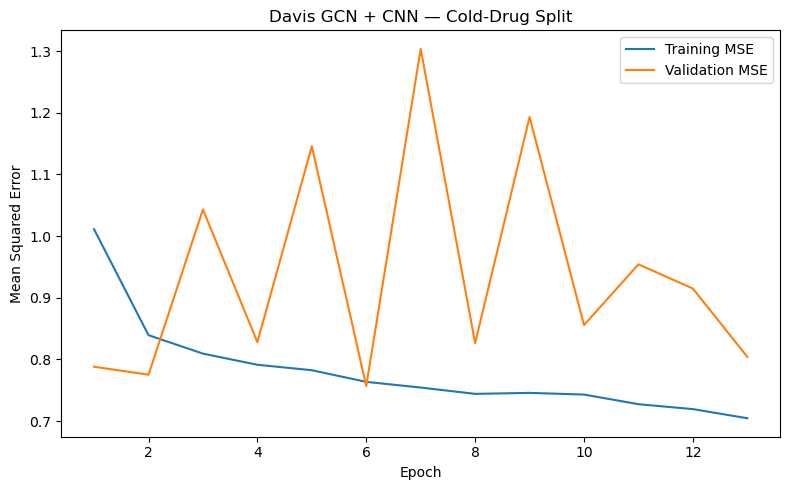

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    cold_drug_gcn_history["epoch"],
    cold_drug_gcn_history["train_mse"],
    label="Training MSE",
)

plt.plot(
    cold_drug_gcn_history["epoch"],
    cold_drug_gcn_history[
        "validation_mse"
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Davis GCN + CNN — Cold-Drug Split")
plt.legend()
plt.tight_layout()

cold_drug_gcn_plot_path = (
    PLOTS_DIR
    / "davis_gcn_cnn_cold_drug_history.png"
)

plt.savefig(
    cold_drug_gcn_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Add the experiment to the log

In [36]:
append_experiment_log(
    dataset="davis",
    model_name="gcn",
    protein_encoder="cnn",
    split_type="cold_drug",
    seed=RANDOM_SEED,
    batch_size=BATCH_SIZE,
    epochs=len(cold_drug_gcn_history),
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    best_validation_mse=(
        cold_drug_gcn_result[
            "best_validation_metrics"
        ]["mse"]
    ),
    test_metrics=cold_drug_gcn_metrics,
    model_path=cold_drug_gcn_checkpoint,
    model=cold_drug_gcn_model,
)

print("Cold-drug GCN experiment logged.")

Cold-drug GCN experiment logged.


# Confirm the outputs

In [37]:
cold_drug_gcn_outputs = [
    cold_drug_gcn_checkpoint,
    cold_drug_gcn_history_path,
    cold_drug_gcn_metrics_path,
    cold_drug_gcn_predictions_path,
    cold_drug_gcn_plot_path,
]

for file_path in cold_drug_gcn_outputs:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in cold_drug_gcn_outputs
)

print(
    "GCN + CNN cold-drug experiment complete."
)

best_davis_gcn_cnn_cold_drug.pt → True
davis_gcn_cnn_cold_drug_history.csv → True
davis_gcn_cnn_cold_drug_metrics.json → True
davis_gcn_cnn_cold_drug_predictions.csv → True
davis_gcn_cnn_cold_drug_history.png → True
GCN + CNN cold-drug experiment complete.


## GAT + CNN — Cold-Drug Evaluation

This experiment trains the GAT + CNN model using the cold-drug split.

The test set contains drugs that were not seen during training.

# Reset the seed and create the model

In [38]:
set_random_seed(RANDOM_SEED)

cold_drug_gat_model = create_dta_model(
    model_name="gat"
).to(device)

print("Model: GAT + CNN")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{count_trainable_parameters(cold_drug_gat_model):,}",
)

Model: GAT + CNN
Device: mps
Trainable parameters: 300,033


# Test one forward pass

In [39]:
example_batch = next(
    iter(cold_drug_train_loader)
).to(device)

cold_drug_gat_model.eval()

with torch.no_grad():
    example_predictions = cold_drug_gat_model(
        example_batch
    )

print("Prediction shape:", example_predictions.shape)
print("True-value shape:", example_batch.y.shape)

assert example_predictions.shape[0] == (
    example_batch.num_graphs
)

assert torch.isfinite(
    example_predictions
).all()

print("GAT + CNN forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GAT + CNN forward pass successful.


# Create the optimiser

In [40]:
cold_drug_gat_optimizer = torch.optim.Adam(
    cold_drug_gat_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", NUM_EPOCHS)
print(
    "Early-stopping patience:",
    EARLY_STOPPING_PATIENCE,
)

Learning rate: 0.001
Weight decay: 1e-05
Maximum epochs: 30
Early-stopping patience: 7


# Set the checkpoint path

In [41]:
cold_drug_gat_checkpoint = (
    MODELS_DIR
    / "best_davis_gat_cnn_cold_drug.pt"
)

print("Model will be saved to:")
print(cold_drug_gat_checkpoint)

Model will be saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gat_cnn_cold_drug.pt


# Train GAT + CNN

In [42]:
cold_drug_gat_result = fit_model(
    model=cold_drug_gat_model,
    train_loader=cold_drug_train_loader,
    validation_loader=cold_drug_validation_loader,
    optimizer=cold_drug_gat_optimizer,
    device=device,
    checkpoint_path=cold_drug_gat_checkpoint,
    num_epochs=NUM_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    metadata={
        "dataset": "davis",
        "model": "gat",
        "protein_encoder": "cnn",
        "split_type": "cold_drug",
        "seed": RANDOM_SEED,
    },
)

Epoch 001 | Train MSE: 1.0061 | Validation MSE: 0.8681 | RMSE: 0.9317 | MAE: 0.5464
Epoch 002 | Train MSE: 0.8258 | Validation MSE: 0.7925 | RMSE: 0.8902 | MAE: 0.6495
Epoch 003 | Train MSE: 0.8009 | Validation MSE: 0.8137 | RMSE: 0.9020 | MAE: 0.6033
Epoch 004 | Train MSE: 0.7623 | Validation MSE: 0.7904 | RMSE: 0.8891 | MAE: 0.6172
Epoch 005 | Train MSE: 0.7492 | Validation MSE: 0.9574 | RMSE: 0.9784 | MAE: 0.5711
Epoch 006 | Train MSE: 0.7544 | Validation MSE: 0.8352 | RMSE: 0.9139 | MAE: 0.6490
Epoch 007 | Train MSE: 0.7241 | Validation MSE: 0.8189 | RMSE: 0.9050 | MAE: 0.6384
Epoch 008 | Train MSE: 0.7108 | Validation MSE: 0.8742 | RMSE: 0.9350 | MAE: 0.6839
Epoch 009 | Train MSE: 0.7096 | Validation MSE: 0.8338 | RMSE: 0.9131 | MAE: 0.6631
Epoch 010 | Train MSE: 0.6893 | Validation MSE: 0.8788 | RMSE: 0.9374 | MAE: 0.6926
Epoch 011 | Train MSE: 0.6658 | Validation MSE: 0.8111 | RMSE: 0.9006 | MAE: 0.5784
Early stopping triggered at epoch 11.


# Show the best validation result

In [43]:
cold_drug_gat_model = cold_drug_gat_result["model"]

print(
    "Best epoch:",
    cold_drug_gat_result["best_epoch"],
)

print("\nBest validation metrics:")

for metric_name, metric_value in (
    cold_drug_gat_result[
        "best_validation_metrics"
    ].items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

Best epoch: 4

Best validation metrics:
mse: 0.7904
rmse: 0.8891
mae: 0.6172
concordance_index: 0.6518
pearson_correlation: 0.3952


# Save the training history

In [44]:
cold_drug_gat_history = pd.DataFrame(
    cold_drug_gat_result["history"]
)

cold_drug_gat_history_path = (
    METRICS_DIR
    / "davis_gat_cnn_cold_drug_history.csv"
)

cold_drug_gat_history.to_csv(
    cold_drug_gat_history_path,
    index=False,
)

display(cold_drug_gat_history.tail())

print("History saved to:")
print(cold_drug_gat_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
6,7,0.724050,0.818941,0.904954,0.638388,0.628782,0.334960
7,8,0.710826,0.874230,0.935002,0.683927,0.605462,0.281232
8,9,0.709579,0.833817,0.913136,0.663054,0.616426,0.312440
9,10,0.689300,0.878796,0.937441,0.692589,0.594429,0.273682
10,11,0.665806,0.811114,0.900619,0.578373,0.653181,0.380132


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gat_cnn_cold_drug_history.csv


# Evaluate on unseen drugs

In [45]:
cold_drug_gat_metrics = evaluate_model(
    model=cold_drug_gat_model,
    data_loader=cold_drug_test_loader,
    device=device,
)

print("GAT + CNN cold-drug test results")

for metric_name, metric_value in (
    cold_drug_gat_metrics.items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

GAT + CNN cold-drug test results
mse: 0.9494
rmse: 0.9744
mae: 0.6956
concordance_index: 0.6804
pearson_correlation: 0.3496


# Save the test metrics

In [46]:
cold_drug_gat_metrics_path = (
    METRICS_DIR
    / "davis_gat_cnn_cold_drug_metrics.json"
)

save_json(
    data=cold_drug_gat_metrics,
    output_path=cold_drug_gat_metrics_path,
)

print("Metrics saved to:")
print(cold_drug_gat_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gat_cnn_cold_drug_metrics.json


# Generate predictions

In [48]:
(
    cold_drug_gat_true_values,
    cold_drug_gat_predicted_values,
    _,
) = predict(
    model=cold_drug_gat_model,
    data_loader=cold_drug_test_loader,
    device=device,
)

print(
    "True values:",
    len(cold_drug_gat_true_values),
)

print(
    "Predicted values:",
    len(cold_drug_gat_predicted_values),
)

True values: 4862
Predicted values: 4862


# Create and save the prediction table

In [49]:
cold_drug_gat_predictions = (
    cold_drug_test_df
    .reset_index(drop=True)
    .copy()
)

assert len(cold_drug_gat_predictions) == len(
    cold_drug_gat_true_values
)

assert len(cold_drug_gat_predictions) == len(
    cold_drug_gat_predicted_values
)

cold_drug_gat_predictions["true_affinity"] = (
    cold_drug_gat_true_values
)

cold_drug_gat_predictions[
    "predicted_affinity"
] = cold_drug_gat_predicted_values

cold_drug_gat_predictions["absolute_error"] = (
    cold_drug_gat_predictions["true_affinity"]
    - cold_drug_gat_predictions[
        "predicted_affinity"
    ]
).abs()

cold_drug_gat_predictions_path = (
    PREDICTIONS_DIR
    / "davis_gat_cnn_cold_drug_predictions.csv"
)

cold_drug_gat_predictions.to_csv(
    cold_drug_gat_predictions_path,
    index=False,
)

print("Predictions saved to:")
print(cold_drug_gat_predictions_path)

display(cold_drug_gat_predictions.head())

Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/davis_gat_cnn_cold_drug_predictions.csv


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,davis,11338033,AAK1,C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...,10000.0,5.0,pKd,5.0,5.520841,0.520841
1,davis,11338033,ABL1(E255K),C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.127085,1.127085
2,davis,11338033,ABL1(F317I),C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.127085,1.127085
3,davis,11338033,ABL1(F317I)p,C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.127085,1.127085
4,davis,11338033,ABL1(F317L),C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.127085,1.127085


# Plot the training history

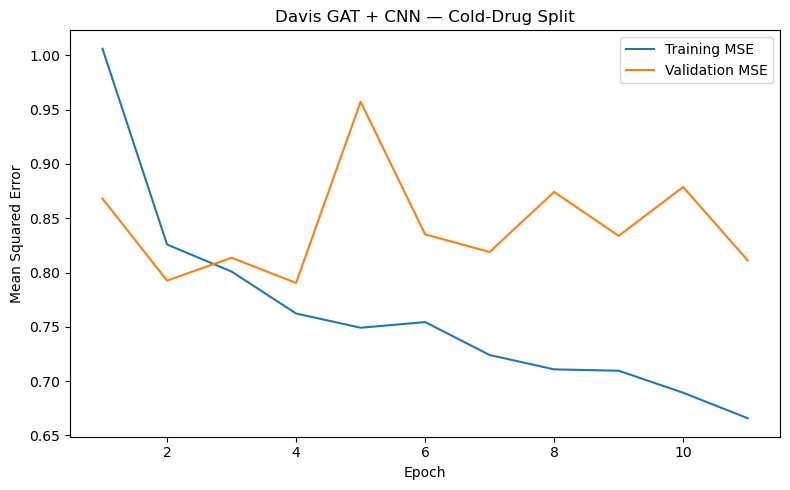

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_gat_cnn_cold_drug_history.png


In [50]:
plt.figure(figsize=(8, 5))

plt.plot(
    cold_drug_gat_history["epoch"],
    cold_drug_gat_history["train_mse"],
    label="Training MSE",
)

plt.plot(
    cold_drug_gat_history["epoch"],
    cold_drug_gat_history[
        "validation_mse"
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Davis GAT + CNN — Cold-Drug Split")
plt.legend()
plt.tight_layout()

cold_drug_gat_plot_path = (
    PLOTS_DIR
    / "davis_gat_cnn_cold_drug_history.png"
)

plt.savefig(
    cold_drug_gat_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(cold_drug_gat_plot_path)

# Add the experiment to the log

In [51]:
append_experiment_log(
    dataset="davis",
    model_name="gat",
    protein_encoder="cnn",
    split_type="cold_drug",
    seed=RANDOM_SEED,
    batch_size=BATCH_SIZE,
    epochs=len(cold_drug_gat_history),
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    best_validation_mse=(
        cold_drug_gat_result[
            "best_validation_metrics"
        ]["mse"]
    ),
    test_metrics=cold_drug_gat_metrics,
    model_path=cold_drug_gat_checkpoint,
    model=cold_drug_gat_model,
)

print("Cold-drug GAT experiment logged.")

Cold-drug GAT experiment logged.


# Confirm all outputs

In [52]:
cold_drug_gat_outputs = [
    cold_drug_gat_checkpoint,
    cold_drug_gat_history_path,
    cold_drug_gat_metrics_path,
    cold_drug_gat_predictions_path,
    cold_drug_gat_plot_path,
]

for file_path in cold_drug_gat_outputs:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in cold_drug_gat_outputs
)

print(
    "GAT + CNN cold-drug experiment complete."
)

best_davis_gat_cnn_cold_drug.pt → True
davis_gat_cnn_cold_drug_history.csv → True
davis_gat_cnn_cold_drug_metrics.json → True
davis_gat_cnn_cold_drug_predictions.csv → True
davis_gat_cnn_cold_drug_history.png → True
GAT + CNN cold-drug experiment complete.


## GIN + CNN — Cold-Drug Evaluation

This experiment trains the GIN + CNN model using the cold-drug split.

The test set contains drugs that were not present during training.

# Reset the seed and create the model

In [53]:
set_random_seed(RANDOM_SEED)

cold_drug_gin_model = create_dta_model(
    model_name="gin"
).to(device)

print("Model: GIN + CNN")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{count_trainable_parameters(cold_drug_gin_model):,}",
)

Model: GIN + CNN
Device: mps
Trainable parameters: 348,801


# Test one forward pass

In [54]:
example_batch = next(
    iter(cold_drug_train_loader)
).to(device)

cold_drug_gin_model.eval()

with torch.no_grad():
    example_predictions = cold_drug_gin_model(
        example_batch
    )

print("Prediction shape:", example_predictions.shape)
print("True-value shape:", example_batch.y.shape)

assert example_predictions.shape[0] == (
    example_batch.num_graphs
)

assert torch.isfinite(
    example_predictions
).all()

print("GIN + CNN forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GIN + CNN forward pass successful.


# Create the optimiser

In [55]:
cold_drug_gin_optimizer = torch.optim.Adam(
    cold_drug_gin_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", NUM_EPOCHS)
print(
    "Early-stopping patience:",
    EARLY_STOPPING_PATIENCE,
)

Learning rate: 0.001
Weight decay: 1e-05
Maximum epochs: 30
Early-stopping patience: 7


# Set the checkpoint path

In [56]:
cold_drug_gin_checkpoint = (
    MODELS_DIR
    / "best_davis_gin_cnn_cold_drug.pt"
)

print("Model will be saved to:")
print(cold_drug_gin_checkpoint)

Model will be saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gin_cnn_cold_drug.pt


# Train GIN + CNN

In [57]:
cold_drug_gin_result = fit_model(
    model=cold_drug_gin_model,
    train_loader=cold_drug_train_loader,
    validation_loader=cold_drug_validation_loader,
    optimizer=cold_drug_gin_optimizer,
    device=device,
    checkpoint_path=cold_drug_gin_checkpoint,
    num_epochs=NUM_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    metadata={
        "dataset": "davis",
        "model": "gin",
        "protein_encoder": "cnn",
        "split_type": "cold_drug",
        "seed": RANDOM_SEED,
    },
)

Epoch 001 | Train MSE: 1.0469 | Validation MSE: 1.1560 | RMSE: 1.0752 | MAE: 0.6729
Epoch 002 | Train MSE: 0.8597 | Validation MSE: 1.1141 | RMSE: 1.0555 | MAE: 0.6616
Epoch 003 | Train MSE: 0.8347 | Validation MSE: 0.7584 | RMSE: 0.8709 | MAE: 0.5780
Epoch 004 | Train MSE: 0.8119 | Validation MSE: 0.7954 | RMSE: 0.8918 | MAE: 0.5573
Epoch 005 | Train MSE: 0.8119 | Validation MSE: 1.2299 | RMSE: 1.1090 | MAE: 0.7363
Epoch 006 | Train MSE: 0.8156 | Validation MSE: 0.8646 | RMSE: 0.9298 | MAE: 0.5591
Epoch 007 | Train MSE: 0.7704 | Validation MSE: 0.9628 | RMSE: 0.9812 | MAE: 0.5858
Epoch 008 | Train MSE: 0.7820 | Validation MSE: 0.8757 | RMSE: 0.9358 | MAE: 0.5824
Epoch 009 | Train MSE: 0.7521 | Validation MSE: 1.0800 | RMSE: 1.0392 | MAE: 0.6700
Epoch 010 | Train MSE: 0.7420 | Validation MSE: 0.8545 | RMSE: 0.9244 | MAE: 0.6690
Early stopping triggered at epoch 10.


# Show the best validation result

In [58]:
cold_drug_gin_model = cold_drug_gin_result["model"]

print(
    "Best epoch:",
    cold_drug_gin_result["best_epoch"],
)

print("\nBest validation metrics:")

for metric_name, metric_value in (
    cold_drug_gin_result[
        "best_validation_metrics"
    ].items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

Best epoch: 3

Best validation metrics:
mse: 0.7584
rmse: 0.8709
mae: 0.5780
concordance_index: 0.7121
pearson_correlation: 0.4363


# Save the training history

In [59]:
cold_drug_gin_history = pd.DataFrame(
    cold_drug_gin_result["history"]
)

cold_drug_gin_history_path = (
    METRICS_DIR
    / "davis_gin_cnn_cold_drug_history.csv"
)

cold_drug_gin_history.to_csv(
    cold_drug_gin_history_path,
    index=False,
)

display(cold_drug_gin_history.tail())

print("History saved to:")
print(cold_drug_gin_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
5,6,0.815582,0.864553,0.929813,0.559116,0.700636,0.438260
6,7,0.770437,0.962827,0.981237,0.585780,0.694107,0.386485
7,8,0.782028,0.875740,0.935810,0.582357,0.668737,0.368425
8,9,0.752141,1.080028,1.039244,0.670014,0.623663,0.276063
9,10,0.741962,0.854511,0.924398,0.669003,0.640762,0.311925


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gin_cnn_cold_drug_history.csv


# Evaluate on unseen drugs

In [60]:
cold_drug_gin_metrics = evaluate_model(
    model=cold_drug_gin_model,
    data_loader=cold_drug_test_loader,
    device=device,
)

print("GIN + CNN cold-drug test results")

for metric_name, metric_value in (
    cold_drug_gin_metrics.items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

GIN + CNN cold-drug test results
mse: 0.8798
rmse: 0.9380
mae: 0.6650
concordance_index: 0.7303
pearson_correlation: 0.4327


# Save the test metrics

In [61]:
cold_drug_gin_metrics_path = (
    METRICS_DIR
    / "davis_gin_cnn_cold_drug_metrics.json"
)

save_json(
    data=cold_drug_gin_metrics,
    output_path=cold_drug_gin_metrics_path,
)

print("Metrics saved to:")
print(cold_drug_gin_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gin_cnn_cold_drug_metrics.json


# Generate predictions

In [62]:
(
    cold_drug_gin_true_values,
    cold_drug_gin_predicted_values,
    _,
) = predict(
    model=cold_drug_gin_model,
    data_loader=cold_drug_test_loader,
    device=device,
)

print(
    "True values:",
    len(cold_drug_gin_true_values),
)

print(
    "Predicted values:",
    len(cold_drug_gin_predicted_values),
)

True values: 4862
Predicted values: 4862


# Create and save the prediction table

In [63]:
cold_drug_gin_predictions = (
    cold_drug_test_df
    .reset_index(drop=True)
    .copy()
)

assert len(cold_drug_gin_predictions) == len(
    cold_drug_gin_true_values
)

assert len(cold_drug_gin_predictions) == len(
    cold_drug_gin_predicted_values
)

cold_drug_gin_predictions["true_affinity"] = (
    cold_drug_gin_true_values
)

cold_drug_gin_predictions[
    "predicted_affinity"
] = cold_drug_gin_predicted_values

cold_drug_gin_predictions["absolute_error"] = (
    cold_drug_gin_predictions["true_affinity"]
    - cold_drug_gin_predictions[
        "predicted_affinity"
    ]
).abs()

cold_drug_gin_predictions_path = (
    PREDICTIONS_DIR
    / "davis_gin_cnn_cold_drug_predictions.csv"
)

cold_drug_gin_predictions.to_csv(
    cold_drug_gin_predictions_path,
    index=False,
)

print("Predictions saved to:")
print(cold_drug_gin_predictions_path)

display(cold_drug_gin_predictions.head())

Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/davis_gin_cnn_cold_drug_predictions.csv


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,davis,11338033,AAK1,C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...,10000.0,5.0,pKd,5.0,5.508655,0.508655
1,davis,11338033,ABL1(E255K),C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.423564,1.423564
2,davis,11338033,ABL1(F317I),C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.423564,1.423564
3,davis,11338033,ABL1(F317I)p,C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.423564,1.423564
4,davis,11338033,ABL1(F317L),C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.0,pKd,5.0,6.423564,1.423564


# Plot the training history

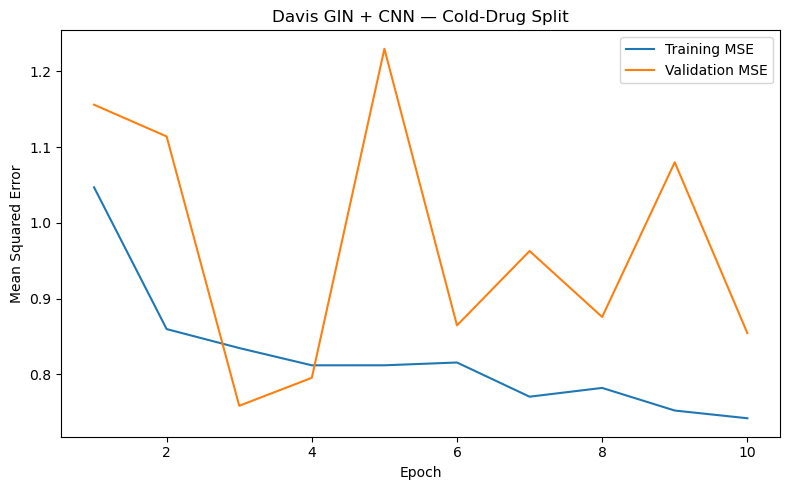

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_gin_cnn_cold_drug_history.png


In [64]:
plt.figure(figsize=(8, 5))

plt.plot(
    cold_drug_gin_history["epoch"],
    cold_drug_gin_history["train_mse"],
    label="Training MSE",
)

plt.plot(
    cold_drug_gin_history["epoch"],
    cold_drug_gin_history[
        "validation_mse"
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Davis GIN + CNN — Cold-Drug Split")
plt.legend()
plt.tight_layout()

cold_drug_gin_plot_path = (
    PLOTS_DIR
    / "davis_gin_cnn_cold_drug_history.png"
)

plt.savefig(
    cold_drug_gin_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(cold_drug_gin_plot_path)

# Add the experiment to the log

In [65]:
append_experiment_log(
    dataset="davis",
    model_name="gin",
    protein_encoder="cnn",
    split_type="cold_drug",
    seed=RANDOM_SEED,
    batch_size=BATCH_SIZE,
    epochs=len(cold_drug_gin_history),
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    best_validation_mse=(
        cold_drug_gin_result[
            "best_validation_metrics"
        ]["mse"]
    ),
    test_metrics=cold_drug_gin_metrics,
    model_path=cold_drug_gin_checkpoint,
    model=cold_drug_gin_model,
)

print("Cold-drug GIN experiment logged.")

Cold-drug GIN experiment logged.


# Confirm all outputs

In [66]:
cold_drug_gin_outputs = [
    cold_drug_gin_checkpoint,
    cold_drug_gin_history_path,
    cold_drug_gin_metrics_path,
    cold_drug_gin_predictions_path,
    cold_drug_gin_plot_path,
]

for file_path in cold_drug_gin_outputs:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in cold_drug_gin_outputs
)

print(
    "GIN + CNN cold-drug experiment complete."
)

best_davis_gin_cnn_cold_drug.pt → True
davis_gin_cnn_cold_drug_history.csv → True
davis_gin_cnn_cold_drug_metrics.json → True
davis_gin_cnn_cold_drug_predictions.csv → True
davis_gin_cnn_cold_drug_history.png → True
GIN + CNN cold-drug experiment complete.


## Cold-Drug Model Comparison

This section compares:

- GCN + CNN
- GAT + CNN
- GIN + CNN

All models used the same cold-drug split and training settings.

Lower MSE, RMSE and MAE are better.

Higher concordance index and Pearson correlation are better.

# Import load_json

In [67]:
from src.utils import load_json

# Load saved cold-drug metrics

In [68]:
cold_drug_gcn_metrics = load_json(
    METRICS_DIR
    / "davis_gcn_cnn_cold_drug_metrics.json"
)

cold_drug_gat_metrics = load_json(
    METRICS_DIR
    / "davis_gat_cnn_cold_drug_metrics.json"
)

cold_drug_gin_metrics = load_json(
    METRICS_DIR
    / "davis_gin_cnn_cold_drug_metrics.json"
)

print("Cold-drug metrics loaded successfully.")

Cold-drug metrics loaded successfully.


# Load training histories

In [69]:
cold_drug_gcn_history = pd.read_csv(
    METRICS_DIR
    / "davis_gcn_cnn_cold_drug_history.csv"
)

cold_drug_gat_history = pd.read_csv(
    METRICS_DIR
    / "davis_gat_cnn_cold_drug_history.csv"
)

cold_drug_gin_history = pd.read_csv(
    METRICS_DIR
    / "davis_gin_cnn_cold_drug_history.csv"
)

print("Cold-drug training histories loaded successfully.")

Cold-drug training histories loaded successfully.


# Count model parameters

In [70]:
cold_drug_gcn_parameters = count_trainable_parameters(
    create_dta_model("gcn")
)

cold_drug_gat_parameters = count_trainable_parameters(
    create_dta_model("gat")
)

cold_drug_gin_parameters = count_trainable_parameters(
    create_dta_model("gin")
)

print("GCN parameters:", f"{cold_drug_gcn_parameters:,}")
print("GAT parameters:", f"{cold_drug_gat_parameters:,}")
print("GIN parameters:", f"{cold_drug_gin_parameters:,}")

GCN parameters: 299,265
GAT parameters: 300,033
GIN parameters: 348,801


# Create the comparison table

In [71]:
cold_drug_comparison_df = pd.DataFrame(
    [
        {
            "model": "GCN + CNN",
            "best_validation_mse": cold_drug_gcn_history[
                "validation_mse"
            ].min(),
            "test_mse": cold_drug_gcn_metrics["mse"],
            "test_rmse": cold_drug_gcn_metrics["rmse"],
            "test_mae": cold_drug_gcn_metrics["mae"],
            "concordance_index": cold_drug_gcn_metrics[
                "concordance_index"
            ],
            "pearson_correlation": cold_drug_gcn_metrics[
                "pearson_correlation"
            ],
            "trainable_parameters": cold_drug_gcn_parameters,
        },
        {
            "model": "GAT + CNN",
            "best_validation_mse": cold_drug_gat_history[
                "validation_mse"
            ].min(),
            "test_mse": cold_drug_gat_metrics["mse"],
            "test_rmse": cold_drug_gat_metrics["rmse"],
            "test_mae": cold_drug_gat_metrics["mae"],
            "concordance_index": cold_drug_gat_metrics[
                "concordance_index"
            ],
            "pearson_correlation": cold_drug_gat_metrics[
                "pearson_correlation"
            ],
            "trainable_parameters": cold_drug_gat_parameters,
        },
        {
            "model": "GIN + CNN",
            "best_validation_mse": cold_drug_gin_history[
                "validation_mse"
            ].min(),
            "test_mse": cold_drug_gin_metrics["mse"],
            "test_rmse": cold_drug_gin_metrics["rmse"],
            "test_mae": cold_drug_gin_metrics["mae"],
            "concordance_index": cold_drug_gin_metrics[
                "concordance_index"
            ],
            "pearson_correlation": cold_drug_gin_metrics[
                "pearson_correlation"
            ],
            "trainable_parameters": cold_drug_gin_parameters,
        },
    ]
)

cold_drug_comparison_df = (
    cold_drug_comparison_df
    .sort_values("best_validation_mse")
    .reset_index(drop=True)
)

cold_drug_comparison_df.insert(
    0,
    "validation_rank",
    range(1, len(cold_drug_comparison_df) + 1),
)

display(cold_drug_comparison_df.round(4))

,validation_rank,model,best_validation_mse,test_mse,test_rmse,test_mae,concordance_index,pearson_correlation,trainable_parameters
0,1,GCN + CNN,0.7567,0.8829,0.9397,0.7265,0.7349,0.4536,299265
1,2,GIN + CNN,0.7584,0.8798,0.9380,0.6650,0.7303,0.4327,348801
2,3,GAT + CNN,0.7904,0.9494,0.9744,0.6956,0.6804,0.3496,300033


# Show the cold-drug winner

In [72]:
cold_drug_best_model = cold_drug_comparison_df.iloc[0]

print("Cold-drug preliminary winner")
print("--------------------------------")
print("Model:", cold_drug_best_model["model"])

print(
    "Best validation MSE:",
    round(
        cold_drug_best_model["best_validation_mse"],
        4,
    ),
)

print(
    "Test RMSE:",
    round(
        cold_drug_best_model["test_rmse"],
        4,
    ),
)

print(
    "Test MAE:",
    round(
        cold_drug_best_model["test_mae"],
        4,
    ),
)

print(
    "Concordance index:",
    round(
        cold_drug_best_model["concordance_index"],
        4,
    ),
)

Cold-drug preliminary winner
--------------------------------
Model: GCN + CNN
Best validation MSE: 0.7567
Test RMSE: 0.9397
Test MAE: 0.7265
Concordance index: 0.7349


# Save the comparison table

In [73]:
cold_drug_comparison_path = (
    METRICS_DIR
    / "davis_cold_drug_model_comparison.csv"
)

cold_drug_comparison_df.to_csv(
    cold_drug_comparison_path,
    index=False,
)

print("Comparison saved to:")
print(cold_drug_comparison_path)

Comparison saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_cold_drug_model_comparison.csv


# Plot cold-drug test RMSE

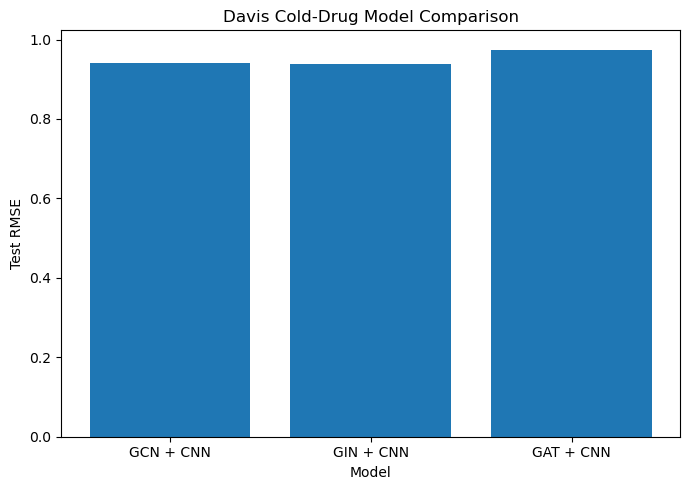

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_cold_drug_rmse_comparison.png


In [74]:
plt.figure(figsize=(7, 5))

plt.bar(
    cold_drug_comparison_df["model"],
    cold_drug_comparison_df["test_rmse"],
)

plt.xlabel("Model")
plt.ylabel("Test RMSE")
plt.title("Davis Cold-Drug Model Comparison")
plt.tight_layout()

cold_drug_rmse_plot_path = (
    PLOTS_DIR
    / "davis_cold_drug_rmse_comparison.png"
)

plt.savefig(
    cold_drug_rmse_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(cold_drug_rmse_plot_path)

# Plot concordance index

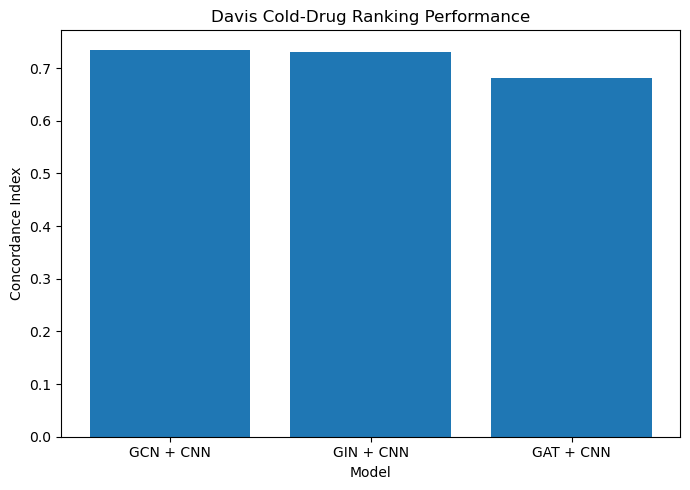

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_cold_drug_ci_comparison.png


In [75]:
plt.figure(figsize=(7, 5))

plt.bar(
    cold_drug_comparison_df["model"],
    cold_drug_comparison_df["concordance_index"],
)

plt.xlabel("Model")
plt.ylabel("Concordance Index")
plt.title("Davis Cold-Drug Ranking Performance")
plt.tight_layout()

cold_drug_ci_plot_path = (
    PLOTS_DIR
    / "davis_cold_drug_ci_comparison.png"
)

plt.savefig(
    cold_drug_ci_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(cold_drug_ci_plot_path)

# Confirm outputs

In [76]:
cold_drug_comparison_outputs = [
    cold_drug_comparison_path,
    cold_drug_rmse_plot_path,
    cold_drug_ci_plot_path,
]

for output_path in cold_drug_comparison_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in cold_drug_comparison_outputs
)

print("Cold-drug model comparison completed successfully.")

davis_cold_drug_model_comparison.csv → True
davis_cold_drug_rmse_comparison.png → True
davis_cold_drug_ci_comparison.png → True
Cold-drug model comparison completed successfully.


## Cold-Drug Evaluation Complete

GCN + CNN, GAT + CNN and GIN + CNN were trained and tested using unseen drugs.

The results were saved in one comparison table, and a preliminary cold-drug winner was identified.

The next section will train the same three models using the cold-target split.

# GCN + CNN on the cold-target split

## GCN + CNN — Cold-Target Evaluation

This experiment trains the GCN + CNN model using the cold-target split.

The test set contains protein targets that were not seen during training.

# Reset the seed and create the model

In [77]:
set_random_seed(RANDOM_SEED)

cold_target_gcn_model = create_dta_model(
    model_name="gcn"
).to(device)

print("Model: GCN + CNN")
print("Split: Cold target")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{count_trainable_parameters(cold_target_gcn_model):,}",
)

Model: GCN + CNN
Split: Cold target
Device: mps
Trainable parameters: 299,265


# Test one forward pass

In [78]:
example_batch = next(
    iter(cold_target_train_loader)
).to(device)

cold_target_gcn_model.eval()

with torch.no_grad():
    example_predictions = cold_target_gcn_model(
        example_batch
    )

print("Prediction shape:", example_predictions.shape)
print("True-value shape:", example_batch.y.shape)

assert example_predictions.shape[0] == (
    example_batch.num_graphs
)

assert torch.isfinite(
    example_predictions
).all()

print("GCN + CNN forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GCN + CNN forward pass successful.


# Create the optimiser

In [79]:
cold_target_gcn_optimizer = torch.optim.Adam(
    cold_target_gcn_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", NUM_EPOCHS)

print(
    "Early-stopping patience:",
    EARLY_STOPPING_PATIENCE,
)

Learning rate: 0.001
Weight decay: 1e-05
Maximum epochs: 30
Early-stopping patience: 7


# Set the checkpoint path

In [80]:
cold_target_gcn_checkpoint = (
    MODELS_DIR
    / "best_davis_gcn_cnn_cold_target.pt"
)

print("Model will be saved to:")
print(cold_target_gcn_checkpoint)

Model will be saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gcn_cnn_cold_target.pt


# Train the model

In [81]:
cold_target_gcn_result = fit_model(
    model=cold_target_gcn_model,
    train_loader=cold_target_train_loader,
    validation_loader=cold_target_validation_loader,
    optimizer=cold_target_gcn_optimizer,
    device=device,
    checkpoint_path=cold_target_gcn_checkpoint,
    num_epochs=NUM_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    metadata={
        "dataset": "davis",
        "model": "gcn",
        "protein_encoder": "cnn",
        "split_type": "cold_target",
        "seed": RANDOM_SEED,
    },
)

Epoch 001 | Train MSE: 1.1182 | Validation MSE: 0.7925 | RMSE: 0.8902 | MAE: 0.6945
Epoch 002 | Train MSE: 0.9115 | Validation MSE: 0.7627 | RMSE: 0.8733 | MAE: 0.5218
Epoch 003 | Train MSE: 0.8974 | Validation MSE: 0.8712 | RMSE: 0.9334 | MAE: 0.5295
Epoch 004 | Train MSE: 0.8769 | Validation MSE: 0.7734 | RMSE: 0.8794 | MAE: 0.5123
Epoch 005 | Train MSE: 0.8576 | Validation MSE: 0.9419 | RMSE: 0.9705 | MAE: 0.5841
Epoch 006 | Train MSE: 0.8436 | Validation MSE: 0.6957 | RMSE: 0.8341 | MAE: 0.5511
Epoch 007 | Train MSE: 0.8321 | Validation MSE: 0.7994 | RMSE: 0.8941 | MAE: 0.7221
Epoch 008 | Train MSE: 0.8353 | Validation MSE: 0.8131 | RMSE: 0.9017 | MAE: 0.5242
Epoch 009 | Train MSE: 0.8220 | Validation MSE: 0.7347 | RMSE: 0.8572 | MAE: 0.5165
Epoch 010 | Train MSE: 0.7989 | Validation MSE: 0.9793 | RMSE: 0.9896 | MAE: 0.6388
Epoch 011 | Train MSE: 0.8083 | Validation MSE: 0.6870 | RMSE: 0.8289 | MAE: 0.5659
Epoch 012 | Train MSE: 0.7970 | Validation MSE: 0.6941 | RMSE: 0.8332 | MAE:

# Show the best validation result

In [82]:
cold_target_gcn_model = cold_target_gcn_result[
    "model"
]

print(
    "Best epoch:",
    cold_target_gcn_result["best_epoch"],
)

print("\nBest validation metrics:")

for metric_name, metric_value in (
    cold_target_gcn_result[
        "best_validation_metrics"
    ].items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

Best epoch: 11

Best validation metrics:
mse: 0.6870
rmse: 0.8289
mae: 0.5659
concordance_index: 0.7219
pearson_correlation: 0.4040


# Save the training history

In [83]:
cold_target_gcn_history = pd.DataFrame(
    cold_target_gcn_result["history"]
)

cold_target_gcn_history_path = (
    METRICS_DIR
    / "davis_gcn_cnn_cold_target_history.csv"
)

cold_target_gcn_history.to_csv(
    cold_target_gcn_history_path,
    index=False,
)

display(cold_target_gcn_history.tail())

print("History saved to:")
print(cold_target_gcn_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
13,14,0.785996,0.691665,0.831664,0.525822,0.720447,0.403068
14,15,0.780959,0.687137,0.828937,0.514336,0.729284,0.416663
15,16,0.775939,0.700435,0.836920,0.510694,0.724325,0.409500
16,17,0.764497,0.696543,0.834591,0.538126,0.724925,0.392611
17,18,0.753676,0.715961,0.846145,0.520170,0.723187,0.414073


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gcn_cnn_cold_target_history.csv


# Evaluate on unseen targets

In [84]:
cold_target_gcn_metrics = evaluate_model(
    model=cold_target_gcn_model,
    data_loader=cold_target_test_loader,
    device=device,
)

print("GCN + CNN cold-target test results")

for metric_name, metric_value in (
    cold_target_gcn_metrics.items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

GCN + CNN cold-target test results
mse: 0.5308
rmse: 0.7286
mae: 0.5066
concordance_index: 0.7126
pearson_correlation: 0.4040


# Save the test metrics

In [85]:
cold_target_gcn_metrics_path = (
    METRICS_DIR
    / "davis_gcn_cnn_cold_target_metrics.json"
)

save_json(
    data=cold_target_gcn_metrics,
    output_path=cold_target_gcn_metrics_path,
)

print("Metrics saved to:")
print(cold_target_gcn_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gcn_cnn_cold_target_metrics.json


# Generate predictions

In [86]:
(
    cold_target_gcn_true_values,
    cold_target_gcn_predicted_values,
    _,
) = predict(
    model=cold_target_gcn_model,
    data_loader=cold_target_test_loader,
    device=device,
)

print(
    "True values:",
    len(cold_target_gcn_true_values),
)

print(
    "Predicted values:",
    len(cold_target_gcn_predicted_values),
)

True values: 4556
Predicted values: 4556


# Create and save the prediction table

In [87]:
cold_target_gcn_predictions = (
    cold_target_test_df
    .reset_index(drop=True)
    .copy()
)

assert len(cold_target_gcn_predictions) == len(
    cold_target_gcn_true_values
)

assert len(cold_target_gcn_predictions) == len(
    cold_target_gcn_predicted_values
)

cold_target_gcn_predictions["true_affinity"] = (
    cold_target_gcn_true_values
)

cold_target_gcn_predictions[
    "predicted_affinity"
] = cold_target_gcn_predicted_values

cold_target_gcn_predictions["absolute_error"] = (
    cold_target_gcn_predictions["true_affinity"]
    - cold_target_gcn_predictions[
        "predicted_affinity"
    ]
).abs()

cold_target_gcn_predictions_path = (
    PREDICTIONS_DIR
    / "davis_gcn_cnn_cold_target_predictions.csv"
)

cold_target_gcn_predictions.to_csv(
    cold_target_gcn_predictions_path,
    index=False,
)

print("Predictions saved to:")
print(cold_target_gcn_predictions_path)

display(cold_target_gcn_predictions.head())

Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/davis_gcn_cnn_cold_target_predictions.csv


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,davis,11314340,ABL1(F317I),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd,5.000000,5.880879,0.880879
1,davis,11314340,ADCK3,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MAAILGDTIMVAKGLVKLTQAAVETHLQHLGIGGELIMAARALQST...,10000.0,5.000000,pKd,5.000000,5.232278,0.232278
2,davis,11314340,AKT2,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MNEVSVIKEGWLHKRGEYIKTWRPRYFLLKSDGSFIGYKERPEAPD...,2900.0,5.537602,pKd,5.537602,5.155825,0.381777
3,davis,11314340,AMPK-alpha2,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MAEKQKHDGRVKIGHYVLGDTLGVGTFGKVKIGEHQLTGHKVAVKI...,10000.0,5.000000,pKd,5.000000,5.199989,0.199989
4,davis,11314340,ANKK1,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MAADPTELRLGSLPVFTRDDFEGDWRLVASGGFSQVFQARHRRWRT...,10000.0,5.000000,pKd,5.000000,5.231129,0.231129


# Plot the training history

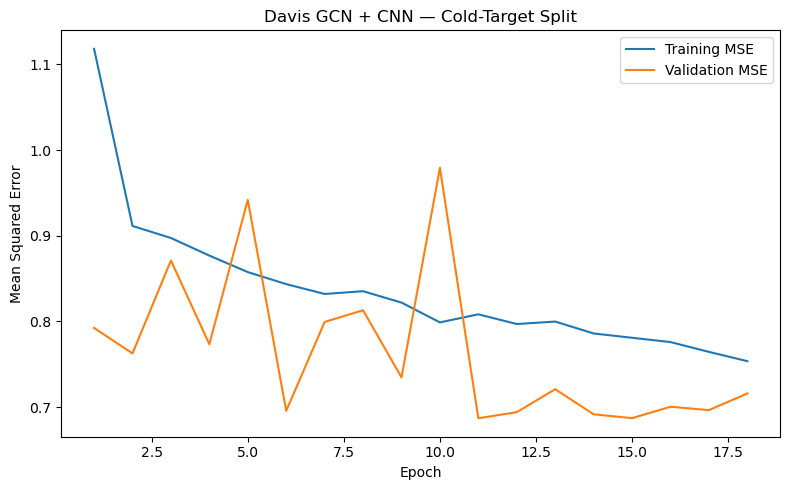

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_gcn_cnn_cold_target_history.png


In [88]:
plt.figure(figsize=(8, 5))

plt.plot(
    cold_target_gcn_history["epoch"],
    cold_target_gcn_history["train_mse"],
    label="Training MSE",
)

plt.plot(
    cold_target_gcn_history["epoch"],
    cold_target_gcn_history[
        "validation_mse"
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Davis GCN + CNN — Cold-Target Split")
plt.legend()
plt.tight_layout()

cold_target_gcn_plot_path = (
    PLOTS_DIR
    / "davis_gcn_cnn_cold_target_history.png"
)

plt.savefig(
    cold_target_gcn_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(cold_target_gcn_plot_path)

# Add the experiment to the log

In [89]:
append_experiment_log(
    dataset="davis",
    model_name="gcn",
    protein_encoder="cnn",
    split_type="cold_target",
    seed=RANDOM_SEED,
    batch_size=BATCH_SIZE,
    epochs=len(cold_target_gcn_history),
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    best_validation_mse=(
        cold_target_gcn_result[
            "best_validation_metrics"
        ]["mse"]
    ),
    test_metrics=cold_target_gcn_metrics,
    model_path=cold_target_gcn_checkpoint,
    model=cold_target_gcn_model,
)

print("Cold-target GCN experiment logged.")

Cold-target GCN experiment logged.


# Confirm all outputs

In [90]:
cold_target_gcn_outputs = [
    cold_target_gcn_checkpoint,
    cold_target_gcn_history_path,
    cold_target_gcn_metrics_path,
    cold_target_gcn_predictions_path,
    cold_target_gcn_plot_path,
]

for file_path in cold_target_gcn_outputs:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in cold_target_gcn_outputs
)

print(
    "GCN + CNN cold-target experiment complete."
)


best_davis_gcn_cnn_cold_target.pt → True
davis_gcn_cnn_cold_target_history.csv → True
davis_gcn_cnn_cold_target_metrics.json → True
davis_gcn_cnn_cold_target_predictions.csv → True
davis_gcn_cnn_cold_target_history.png → True
GCN + CNN cold-target experiment complete.


## GAT + CNN — Cold-Target Evaluation

This experiment trains the GAT + CNN model using the cold-target split.

The test set contains protein targets that were not present during training.

# Reset the seed and create the model

In [91]:
set_random_seed(RANDOM_SEED)

cold_target_gat_model = create_dta_model(
    model_name="gat"
).to(device)

print("Model: GAT + CNN")
print("Split: Cold target")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{count_trainable_parameters(cold_target_gat_model):,}",
)

Model: GAT + CNN
Split: Cold target
Device: mps
Trainable parameters: 300,033


# Test one forward pass

In [92]:
example_batch = next(
    iter(cold_target_train_loader)
).to(device)

cold_target_gat_model.eval()

with torch.no_grad():
    example_predictions = cold_target_gat_model(
        example_batch
    )

print("Prediction shape:", example_predictions.shape)
print("True-value shape:", example_batch.y.shape)

assert example_predictions.shape[0] == (
    example_batch.num_graphs
)

assert torch.isfinite(
    example_predictions
).all()

print("GAT + CNN forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GAT + CNN forward pass successful.


# Create the optimiser

In [93]:
cold_target_gat_optimizer = torch.optim.Adam(
    cold_target_gat_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", NUM_EPOCHS)

print(
    "Early-stopping patience:",
    EARLY_STOPPING_PATIENCE,
)

Learning rate: 0.001
Weight decay: 1e-05
Maximum epochs: 30
Early-stopping patience: 7


# Set the checkpoint path

In [94]:
cold_target_gat_checkpoint = (
    MODELS_DIR
    / "best_davis_gat_cnn_cold_target.pt"
)

print("Model will be saved to:")
print(cold_target_gat_checkpoint)

Model will be saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gat_cnn_cold_target.pt


# Train GAT + CNN

In [95]:
cold_target_gat_result = fit_model(
    model=cold_target_gat_model,
    train_loader=cold_target_train_loader,
    validation_loader=cold_target_validation_loader,
    optimizer=cold_target_gat_optimizer,
    device=device,
    checkpoint_path=cold_target_gat_checkpoint,
    num_epochs=NUM_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    metadata={
        "dataset": "davis",
        "model": "gat",
        "protein_encoder": "cnn",
        "split_type": "cold_target",
        "seed": RANDOM_SEED,
    },
)

Epoch 001 | Train MSE: 1.1330 | Validation MSE: 0.7414 | RMSE: 0.8611 | MAE: 0.5872
Epoch 002 | Train MSE: 0.9153 | Validation MSE: 0.8203 | RMSE: 0.9057 | MAE: 0.5143
Epoch 003 | Train MSE: 0.8929 | Validation MSE: 0.7298 | RMSE: 0.8543 | MAE: 0.5938
Epoch 004 | Train MSE: 0.8721 | Validation MSE: 0.7496 | RMSE: 0.8658 | MAE: 0.6649
Epoch 005 | Train MSE: 0.8421 | Validation MSE: 0.6922 | RMSE: 0.8320 | MAE: 0.5321
Epoch 006 | Train MSE: 0.8267 | Validation MSE: 0.6908 | RMSE: 0.8312 | MAE: 0.5806
Epoch 007 | Train MSE: 0.8145 | Validation MSE: 0.6891 | RMSE: 0.8301 | MAE: 0.4963
Epoch 008 | Train MSE: 0.7909 | Validation MSE: 0.6836 | RMSE: 0.8268 | MAE: 0.5314
Epoch 009 | Train MSE: 0.7739 | Validation MSE: 0.6669 | RMSE: 0.8166 | MAE: 0.5662
Epoch 010 | Train MSE: 0.7724 | Validation MSE: 0.6581 | RMSE: 0.8112 | MAE: 0.5275
Epoch 011 | Train MSE: 0.7443 | Validation MSE: 0.7193 | RMSE: 0.8481 | MAE: 0.6759
Epoch 012 | Train MSE: 0.7354 | Validation MSE: 0.6603 | RMSE: 0.8126 | MAE:

# Show the best validation result

In [96]:
cold_target_gat_model = cold_target_gat_result[
    "model"
]

print(
    "Best epoch:",
    cold_target_gat_result["best_epoch"],
)

print("\nBest validation metrics:")

for metric_name, metric_value in (
    cold_target_gat_result[
        "best_validation_metrics"
    ].items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

Best epoch: 30

Best validation metrics:
mse: 0.5124
rmse: 0.7158
mae: 0.4426
concordance_index: 0.8064
pearson_correlation: 0.6119


# Save the training history

In [97]:
cold_target_gat_history = pd.DataFrame(
    cold_target_gat_result["history"]
)

cold_target_gat_history_path = (
    METRICS_DIR
    / "davis_gat_cnn_cold_target_history.csv"
)

cold_target_gat_history.to_csv(
    cold_target_gat_history_path,
    index=False,
)

display(cold_target_gat_history.tail())

print("History saved to:")
print(cold_target_gat_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
25,26,0.583228,0.558154,0.747097,0.431907,0.794797,0.583465
26,27,0.574880,0.560172,0.748446,0.509615,0.786883,0.571384
27,28,0.573053,0.574892,0.758216,0.434023,0.796208,0.598454
28,29,0.564201,0.547793,0.740130,0.494802,0.798704,0.582564
29,30,0.565050,0.512439,0.715849,0.442594,0.806389,0.611885


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gat_cnn_cold_target_history.csv


# Evaluate on unseen targets

In [98]:
cold_target_gat_metrics = evaluate_model(
    model=cold_target_gat_model,
    data_loader=cold_target_test_loader,
    device=device,
)

print("GAT + CNN cold-target test results")

for metric_name, metric_value in (
    cold_target_gat_metrics.items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

GAT + CNN cold-target test results
mse: 0.4059
rmse: 0.6371
mae: 0.3966
concordance_index: 0.8031
pearson_correlation: 0.5987


# Save the test metrics

In [99]:
cold_target_gat_metrics_path = (
    METRICS_DIR
    / "davis_gat_cnn_cold_target_metrics.json"
)

save_json(
    data=cold_target_gat_metrics,
    output_path=cold_target_gat_metrics_path,
)

print("Metrics saved to:")
print(cold_target_gat_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gat_cnn_cold_target_metrics.json


# Generate predictions

In [100]:
(
    cold_target_gat_true_values,
    cold_target_gat_predicted_values,
    _,
) = predict(
    model=cold_target_gat_model,
    data_loader=cold_target_test_loader,
    device=device,
)

print(
    "True values:",
    len(cold_target_gat_true_values),
)

print(
    "Predicted values:",
    len(cold_target_gat_predicted_values),
)

True values: 4556
Predicted values: 4556


# Create and save the prediction table

In [101]:
cold_target_gat_predictions = (
    cold_target_test_df
    .reset_index(drop=True)
    .copy()
)

assert len(cold_target_gat_predictions) == len(
    cold_target_gat_true_values
)

assert len(cold_target_gat_predictions) == len(
    cold_target_gat_predicted_values
)

cold_target_gat_predictions["true_affinity"] = (
    cold_target_gat_true_values
)

cold_target_gat_predictions[
    "predicted_affinity"
] = cold_target_gat_predicted_values

cold_target_gat_predictions["absolute_error"] = (
    cold_target_gat_predictions["true_affinity"]
    - cold_target_gat_predictions[
        "predicted_affinity"
    ]
).abs()

cold_target_gat_predictions_path = (
    PREDICTIONS_DIR
    / "davis_gat_cnn_cold_target_predictions.csv"
)

cold_target_gat_predictions.to_csv(
    cold_target_gat_predictions_path,
    index=False,
)

print("Predictions saved to:")
print(cold_target_gat_predictions_path)

display(cold_target_gat_predictions.head())

Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/davis_gat_cnn_cold_target_predictions.csv


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,davis,11314340,ABL1(F317I),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd,5.000000,5.192303,0.192303
1,davis,11314340,ADCK3,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MAAILGDTIMVAKGLVKLTQAAVETHLQHLGIGGELIMAARALQST...,10000.0,5.000000,pKd,5.000000,5.449747,0.449747
2,davis,11314340,AKT2,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MNEVSVIKEGWLHKRGEYIKTWRPRYFLLKSDGSFIGYKERPEAPD...,2900.0,5.537602,pKd,5.537602,5.788642,0.251040
3,davis,11314340,AMPK-alpha2,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MAEKQKHDGRVKIGHYVLGDTLGVGTFGKVKIGEHQLTGHKVAVKI...,10000.0,5.000000,pKd,5.000000,5.599967,0.599967
4,davis,11314340,ANKK1,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MAADPTELRLGSLPVFTRDDFEGDWRLVASGGFSQVFQARHRRWRT...,10000.0,5.000000,pKd,5.000000,5.529079,0.529079


# Plot the training history

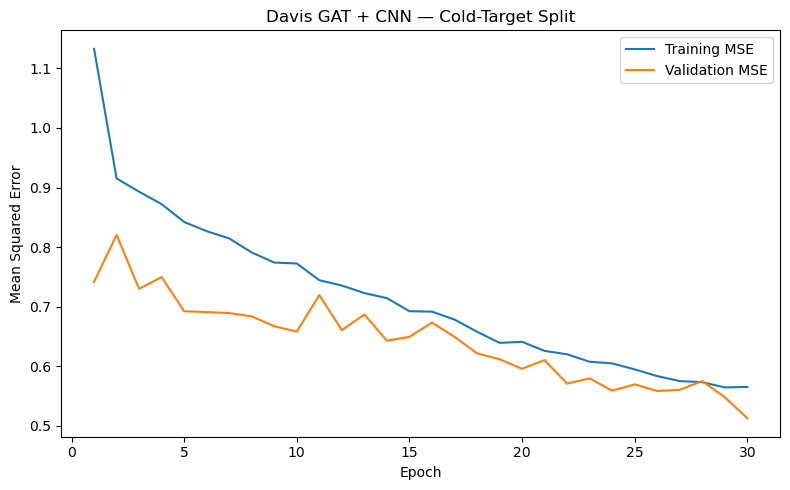

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_gat_cnn_cold_target_history.png


In [102]:
plt.figure(figsize=(8, 5))

plt.plot(
    cold_target_gat_history["epoch"],
    cold_target_gat_history["train_mse"],
    label="Training MSE",
)

plt.plot(
    cold_target_gat_history["epoch"],
    cold_target_gat_history[
        "validation_mse"
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Davis GAT + CNN — Cold-Target Split")
plt.legend()
plt.tight_layout()

cold_target_gat_plot_path = (
    PLOTS_DIR
    / "davis_gat_cnn_cold_target_history.png"
)

plt.savefig(
    cold_target_gat_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(cold_target_gat_plot_path)

# Add the experiment to the log

In [103]:
append_experiment_log(
    dataset="davis",
    model_name="gat",
    protein_encoder="cnn",
    split_type="cold_target",
    seed=RANDOM_SEED,
    batch_size=BATCH_SIZE,
    epochs=len(cold_target_gat_history),
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    best_validation_mse=(
        cold_target_gat_result[
            "best_validation_metrics"
        ]["mse"]
    ),
    test_metrics=cold_target_gat_metrics,
    model_path=cold_target_gat_checkpoint,
    model=cold_target_gat_model,
)

print("Cold-target GAT experiment logged.")

Cold-target GAT experiment logged.


# Confirm all outputs

In [104]:
cold_target_gat_outputs = [
    cold_target_gat_checkpoint,
    cold_target_gat_history_path,
    cold_target_gat_metrics_path,
    cold_target_gat_predictions_path,
    cold_target_gat_plot_path,
]

for file_path in cold_target_gat_outputs:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in cold_target_gat_outputs
)

print(
    "GAT + CNN cold-target experiment complete."
)

best_davis_gat_cnn_cold_target.pt → True
davis_gat_cnn_cold_target_history.csv → True
davis_gat_cnn_cold_target_metrics.json → True
davis_gat_cnn_cold_target_predictions.csv → True
davis_gat_cnn_cold_target_history.png → True
GAT + CNN cold-target experiment complete.


## GIN + CNN — Cold-Target Evaluation

This experiment trains the GIN + CNN model using the cold-target split.

The test set contains protein targets that were not used during training.

# Create the GIN model

In [105]:
set_random_seed(RANDOM_SEED)

cold_target_gin_model = create_dta_model(
    model_name="gin"
).to(device)

print("Model: GIN + CNN")
print("Split: Cold target")
print("Device:", device)

print(
    "Trainable parameters:",
    f"{count_trainable_parameters(cold_target_gin_model):,}",
)

Model: GIN + CNN
Split: Cold target
Device: mps
Trainable parameters: 348,801


# Test one forward pass

In [106]:
example_batch = next(
    iter(cold_target_train_loader)
).to(device)

cold_target_gin_model.eval()

with torch.no_grad():
    example_predictions = cold_target_gin_model(
        example_batch
    )

print("Prediction shape:", example_predictions.shape)
print("True-value shape:", example_batch.y.shape)

assert example_predictions.shape[0] == (
    example_batch.num_graphs
)

assert torch.isfinite(example_predictions).all()

print("GIN + CNN forward pass successful.")

Prediction shape: torch.Size([32])
True-value shape: torch.Size([32])
GIN + CNN forward pass successful.


# Create the optimiser

In [107]:
cold_target_gin_optimizer = torch.optim.Adam(
    cold_target_gin_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", NUM_EPOCHS)
print(
    "Early-stopping patience:",
    EARLY_STOPPING_PATIENCE,
)

Learning rate: 0.001
Weight decay: 1e-05
Maximum epochs: 30
Early-stopping patience: 7


# Set the model save path

In [108]:
cold_target_gin_checkpoint = (
    MODELS_DIR
    / "best_davis_gin_cnn_cold_target.pt"
)

print("Model will be saved to:")
print(cold_target_gin_checkpoint)

Model will be saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/models/best_davis_gin_cnn_cold_target.pt


# Train GIN + CNN

In [109]:
cold_target_gin_result = fit_model(
    model=cold_target_gin_model,
    train_loader=cold_target_train_loader,
    validation_loader=cold_target_validation_loader,
    optimizer=cold_target_gin_optimizer,
    device=device,
    checkpoint_path=cold_target_gin_checkpoint,
    num_epochs=NUM_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    metadata={
        "dataset": "davis",
        "model": "gin",
        "protein_encoder": "cnn",
        "split_type": "cold_target",
        "seed": RANDOM_SEED,
    },
)

Epoch 001 | Train MSE: 1.1568 | Validation MSE: 1.1995 | RMSE: 1.0952 | MAE: 0.7268
Epoch 002 | Train MSE: 0.9501 | Validation MSE: 0.7313 | RMSE: 0.8552 | MAE: 0.5929
Epoch 003 | Train MSE: 0.8947 | Validation MSE: 0.9744 | RMSE: 0.9871 | MAE: 0.6120
Epoch 004 | Train MSE: 0.8978 | Validation MSE: 0.7286 | RMSE: 0.8536 | MAE: 0.5719
Epoch 005 | Train MSE: 0.9005 | Validation MSE: 0.7399 | RMSE: 0.8602 | MAE: 0.5583
Epoch 006 | Train MSE: 0.8836 | Validation MSE: 0.7851 | RMSE: 0.8860 | MAE: 0.6682
Epoch 007 | Train MSE: 0.8665 | Validation MSE: 0.9833 | RMSE: 0.9916 | MAE: 0.6560
Epoch 008 | Train MSE: 0.8678 | Validation MSE: 1.1603 | RMSE: 1.0772 | MAE: 0.7451
Epoch 009 | Train MSE: 0.8450 | Validation MSE: 0.8631 | RMSE: 0.9291 | MAE: 0.5850
Epoch 010 | Train MSE: 0.8291 | Validation MSE: 0.9669 | RMSE: 0.9833 | MAE: 0.6378
Epoch 011 | Train MSE: 0.8257 | Validation MSE: 0.7059 | RMSE: 0.8402 | MAE: 0.5790
Epoch 012 | Train MSE: 0.8015 | Validation MSE: 0.8929 | RMSE: 0.9449 | MAE:

# Show the best validation result

In [110]:
cold_target_gin_model = cold_target_gin_result[
    "model"
]

print(
    "Best epoch:",
    cold_target_gin_result["best_epoch"],
)

print("\nBest validation metrics:")

for metric_name, metric_value in (
    cold_target_gin_result[
        "best_validation_metrics"
    ].items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

Best epoch: 22

Best validation metrics:
mse: 0.6342
rmse: 0.7964
mae: 0.4892
concordance_index: 0.7615
pearson_correlation: 0.4907


# Save the training history

In [111]:
cold_target_gin_history = pd.DataFrame(
    cold_target_gin_result["history"]
)

cold_target_gin_history_path = (
    METRICS_DIR
    / "davis_gin_cnn_cold_target_history.csv"
)

cold_target_gin_history.to_csv(
    cold_target_gin_history_path,
    index=False,
)

display(cold_target_gin_history.tail())

print("History saved to:")
print(cold_target_gin_history_path)

,epoch,train_mse,validation_mse,validation_rmse,validation_mae,validation_concordance_index,validation_pearson_correlation
24,25,0.676384,0.793853,0.890984,0.558429,0.754776,0.476044
25,26,0.669940,0.681110,0.825294,0.505222,0.758602,0.492140
26,27,0.669953,0.657886,0.811102,0.479820,0.761257,0.476087
27,28,0.668602,0.673489,0.820664,0.485840,0.761550,0.497987
28,29,0.658433,0.651677,0.807265,0.477940,0.764593,0.496792


History saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gin_cnn_cold_target_history.csv


# Evaluate on unseen targets

In [112]:
cold_target_gin_metrics = evaluate_model(
    model=cold_target_gin_model,
    data_loader=cold_target_test_loader,
    device=device,
)

print("GIN + CNN cold-target test results")

for metric_name, metric_value in (
    cold_target_gin_metrics.items()
):
    print(
        f"{metric_name}: {metric_value:.4f}"
    )

GIN + CNN cold-target test results
mse: 0.4862
rmse: 0.6973
mae: 0.4272
concordance_index: 0.7631
pearson_correlation: 0.5056


# Save the test metrics

In [113]:
cold_target_gin_metrics_path = (
    METRICS_DIR
    / "davis_gin_cnn_cold_target_metrics.json"
)

save_json(
    data=cold_target_gin_metrics,
    output_path=cold_target_gin_metrics_path,
)

print("Metrics saved to:")
print(cold_target_gin_metrics_path)

Metrics saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_gin_cnn_cold_target_metrics.json


# Generate predictions

In [114]:
(
    cold_target_gin_true_values,
    cold_target_gin_predicted_values,
    _,
) = predict(
    model=cold_target_gin_model,
    data_loader=cold_target_test_loader,
    device=device,
)

print(
    "True values:",
    len(cold_target_gin_true_values),
)

print(
    "Predicted values:",
    len(cold_target_gin_predicted_values),
)

True values: 4556
Predicted values: 4556


# Create and save prediction table

In [115]:
cold_target_gin_predictions = (
    cold_target_test_df
    .reset_index(drop=True)
    .copy()
)

assert len(cold_target_gin_predictions) == len(
    cold_target_gin_true_values
)

assert len(cold_target_gin_predictions) == len(
    cold_target_gin_predicted_values
)

cold_target_gin_predictions["true_affinity"] = (
    cold_target_gin_true_values
)

cold_target_gin_predictions[
    "predicted_affinity"
] = cold_target_gin_predicted_values

cold_target_gin_predictions["absolute_error"] = (
    cold_target_gin_predictions["true_affinity"]
    - cold_target_gin_predictions[
        "predicted_affinity"
    ]
).abs()

cold_target_gin_predictions_path = (
    PREDICTIONS_DIR
    / "davis_gin_cnn_cold_target_predictions.csv"
)

cold_target_gin_predictions.to_csv(
    cold_target_gin_predictions_path,
    index=False,
)

print("Predictions saved to:")
print(cold_target_gin_predictions_path)

display(cold_target_gin_predictions.head())

Predictions saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/predictions/davis_gin_cnn_cold_target_predictions.csv


,dataset,drug_id,target_id,smiles,protein_sequence,raw_affinity,affinity,affinity_type,true_affinity,predicted_affinity,absolute_error
0,davis,11314340,ABL1(F317I),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,10000.0,5.000000,pKd,5.000000,5.887166,0.887166
1,davis,11314340,ADCK3,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MAAILGDTIMVAKGLVKLTQAAVETHLQHLGIGGELIMAARALQST...,10000.0,5.000000,pKd,5.000000,5.006149,0.006149
2,davis,11314340,AKT2,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MNEVSVIKEGWLHKRGEYIKTWRPRYFLLKSDGSFIGYKERPEAPD...,2900.0,5.537602,pKd,5.537602,4.877951,0.659651
3,davis,11314340,AMPK-alpha2,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MAEKQKHDGRVKIGHYVLGDTLGVGTFGKVKIGEHQLTGHKVAVKI...,10000.0,5.000000,pKd,5.000000,5.062618,0.062618
4,davis,11314340,ANKK1,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MAADPTELRLGSLPVFTRDDFEGDWRLVASGGFSQVFQARHRRWRT...,10000.0,5.000000,pKd,5.000000,5.111083,0.111083


# Plot training history

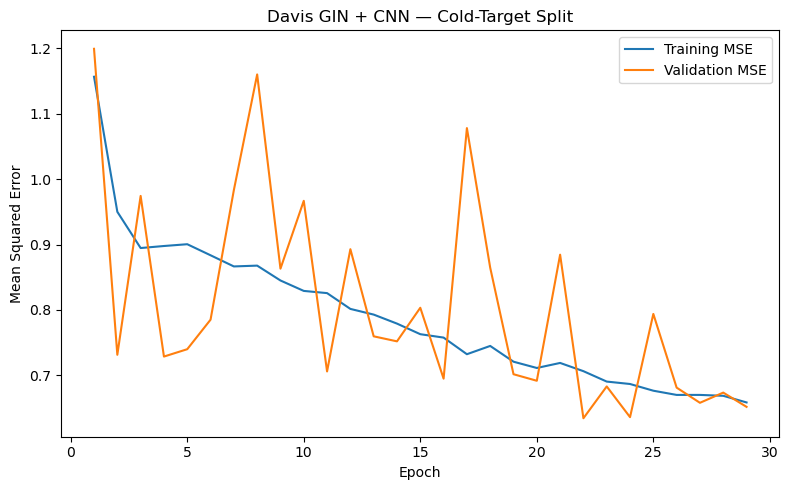

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_gin_cnn_cold_target_history.png


In [116]:
plt.figure(figsize=(8, 5))

plt.plot(
    cold_target_gin_history["epoch"],
    cold_target_gin_history["train_mse"],
    label="Training MSE",
)

plt.plot(
    cold_target_gin_history["epoch"],
    cold_target_gin_history[
        "validation_mse"
    ],
    label="Validation MSE",
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Davis GIN + CNN — Cold-Target Split")
plt.legend()
plt.tight_layout()

cold_target_gin_plot_path = (
    PLOTS_DIR
    / "davis_gin_cnn_cold_target_history.png"
)

plt.savefig(
    cold_target_gin_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(cold_target_gin_plot_path)

# Add the experiment to the log

In [117]:
append_experiment_log(
    dataset="davis",
    model_name="gin",
    protein_encoder="cnn",
    split_type="cold_target",
    seed=RANDOM_SEED,
    batch_size=BATCH_SIZE,
    epochs=len(cold_target_gin_history),
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    best_validation_mse=(
        cold_target_gin_result[
            "best_validation_metrics"
        ]["mse"]
    ),
    test_metrics=cold_target_gin_metrics,
    model_path=cold_target_gin_checkpoint,
    model=cold_target_gin_model,
)

print("Cold-target GIN experiment logged.")

Cold-target GIN experiment logged.


# Confirm all outputs

In [118]:
cold_target_gin_outputs = [
    cold_target_gin_checkpoint,
    cold_target_gin_history_path,
    cold_target_gin_metrics_path,
    cold_target_gin_predictions_path,
    cold_target_gin_plot_path,
]

for file_path in cold_target_gin_outputs:
    print(
        file_path.name,
        "→",
        file_path.exists(),
    )

assert all(
    file_path.exists()
    for file_path in cold_target_gin_outputs
)

print(
    "GIN + CNN cold-target experiment complete."
)

best_davis_gin_cnn_cold_target.pt → True
davis_gin_cnn_cold_target_history.csv → True
davis_gin_cnn_cold_target_metrics.json → True
davis_gin_cnn_cold_target_predictions.csv → True
davis_gin_cnn_cold_target_history.png → True
GIN + CNN cold-target experiment complete.


## Cold-Target Model Comparison

This section compares:

- GCN + CNN
- GAT + CNN
- GIN + CNN

All models used the same cold-target split and training settings.

Lower MSE, RMSE and MAE are better.

Higher concordance index and Pearson correlation are better.

# Load the saved cold-target metrics

In [119]:
cold_target_gcn_metrics = load_json(
    METRICS_DIR
    / "davis_gcn_cnn_cold_target_metrics.json"
)

cold_target_gat_metrics = load_json(
    METRICS_DIR
    / "davis_gat_cnn_cold_target_metrics.json"
)

cold_target_gin_metrics = load_json(
    METRICS_DIR
    / "davis_gin_cnn_cold_target_metrics.json"
)

print("Cold-target metrics loaded successfully.")

Cold-target metrics loaded successfully.


# Load the training histories

In [120]:
cold_target_gcn_history = pd.read_csv(
    METRICS_DIR
    / "davis_gcn_cnn_cold_target_history.csv"
)

cold_target_gat_history = pd.read_csv(
    METRICS_DIR
    / "davis_gat_cnn_cold_target_history.csv"
)

cold_target_gin_history = pd.read_csv(
    METRICS_DIR
    / "davis_gin_cnn_cold_target_history.csv"
)

print("Cold-target training histories loaded successfully.")

Cold-target training histories loaded successfully.


# Count model parameters

In [121]:
cold_target_gcn_parameters = count_trainable_parameters(
    create_dta_model("gcn")
)

cold_target_gat_parameters = count_trainable_parameters(
    create_dta_model("gat")
)

cold_target_gin_parameters = count_trainable_parameters(
    create_dta_model("gin")
)

print("GCN parameters:", f"{cold_target_gcn_parameters:,}")
print("GAT parameters:", f"{cold_target_gat_parameters:,}")
print("GIN parameters:", f"{cold_target_gin_parameters:,}")

GCN parameters: 299,265
GAT parameters: 300,033
GIN parameters: 348,801


# Create the comparison table

In [122]:
cold_target_comparison_df = pd.DataFrame(
    [
        {
            "model": "GCN + CNN",
            "best_validation_mse": cold_target_gcn_history[
                "validation_mse"
            ].min(),
            "test_mse": cold_target_gcn_metrics["mse"],
            "test_rmse": cold_target_gcn_metrics["rmse"],
            "test_mae": cold_target_gcn_metrics["mae"],
            "concordance_index": cold_target_gcn_metrics[
                "concordance_index"
            ],
            "pearson_correlation": cold_target_gcn_metrics[
                "pearson_correlation"
            ],
            "trainable_parameters": cold_target_gcn_parameters,
        },
        {
            "model": "GAT + CNN",
            "best_validation_mse": cold_target_gat_history[
                "validation_mse"
            ].min(),
            "test_mse": cold_target_gat_metrics["mse"],
            "test_rmse": cold_target_gat_metrics["rmse"],
            "test_mae": cold_target_gat_metrics["mae"],
            "concordance_index": cold_target_gat_metrics[
                "concordance_index"
            ],
            "pearson_correlation": cold_target_gat_metrics[
                "pearson_correlation"
            ],
            "trainable_parameters": cold_target_gat_parameters,
        },
        {
            "model": "GIN + CNN",
            "best_validation_mse": cold_target_gin_history[
                "validation_mse"
            ].min(),
            "test_mse": cold_target_gin_metrics["mse"],
            "test_rmse": cold_target_gin_metrics["rmse"],
            "test_mae": cold_target_gin_metrics["mae"],
            "concordance_index": cold_target_gin_metrics[
                "concordance_index"
            ],
            "pearson_correlation": cold_target_gin_metrics[
                "pearson_correlation"
            ],
            "trainable_parameters": cold_target_gin_parameters,
        },
    ]
)

cold_target_comparison_df = (
    cold_target_comparison_df
    .sort_values("best_validation_mse")
    .reset_index(drop=True)
)

cold_target_comparison_df.insert(
    0,
    "validation_rank",
    range(1, len(cold_target_comparison_df) + 1),
)

display(cold_target_comparison_df.round(4))

,validation_rank,model,best_validation_mse,test_mse,test_rmse,test_mae,concordance_index,pearson_correlation,trainable_parameters
0,1,GAT + CNN,0.5124,0.4059,0.6371,0.3966,0.8031,0.5987,300033
1,2,GIN + CNN,0.6342,0.4862,0.6973,0.4272,0.7631,0.5056,348801
2,3,GCN + CNN,0.6870,0.5308,0.7286,0.5066,0.7126,0.4040,299265


# Show the cold-target winner

In [123]:
cold_target_best_model = cold_target_comparison_df.iloc[0]

print("Cold-target preliminary winner")
print("--------------------------------")
print("Model:", cold_target_best_model["model"])

print(
    "Best validation MSE:",
    round(
        cold_target_best_model["best_validation_mse"],
        4,
    ),
)

print(
    "Test RMSE:",
    round(
        cold_target_best_model["test_rmse"],
        4,
    ),
)

print(
    "Test MAE:",
    round(
        cold_target_best_model["test_mae"],
        4,
    ),
)

print(
    "Concordance index:",
    round(
        cold_target_best_model["concordance_index"],
        4,
    ),
)

print(
    "Pearson correlation:",
    round(
        cold_target_best_model["pearson_correlation"],
        4,
    ),
)

Cold-target preliminary winner
--------------------------------
Model: GAT + CNN
Best validation MSE: 0.5124
Test RMSE: 0.6371
Test MAE: 0.3966
Concordance index: 0.8031
Pearson correlation: 0.5987


# Save the comparison table

In [124]:
cold_target_comparison_path = (
    METRICS_DIR
    / "davis_cold_target_model_comparison.csv"
)

cold_target_comparison_df.to_csv(
    cold_target_comparison_path,
    index=False,
)

print("Comparison saved to:")
print(cold_target_comparison_path)

Comparison saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_cold_target_model_comparison.csv


# Plot test RMSE

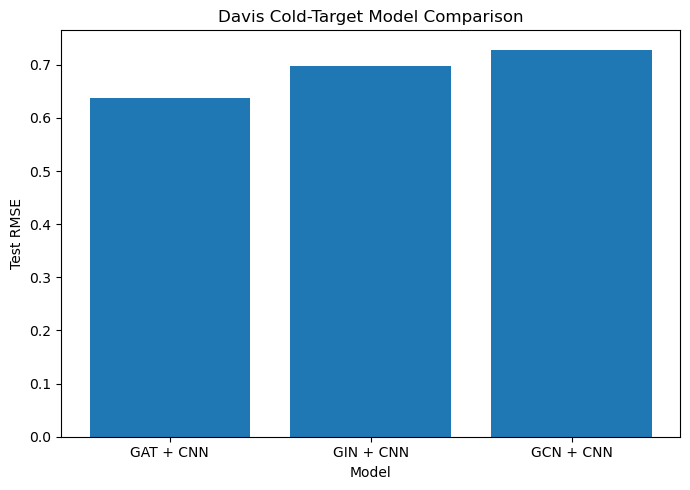

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_cold_target_rmse_comparison.png


In [125]:
plt.figure(figsize=(7, 5))

plt.bar(
    cold_target_comparison_df["model"],
    cold_target_comparison_df["test_rmse"],
)

plt.xlabel("Model")
plt.ylabel("Test RMSE")
plt.title("Davis Cold-Target Model Comparison")
plt.tight_layout()

cold_target_rmse_plot_path = (
    PLOTS_DIR
    / "davis_cold_target_rmse_comparison.png"
)

plt.savefig(
    cold_target_rmse_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(cold_target_rmse_plot_path)

# Plot concordance index

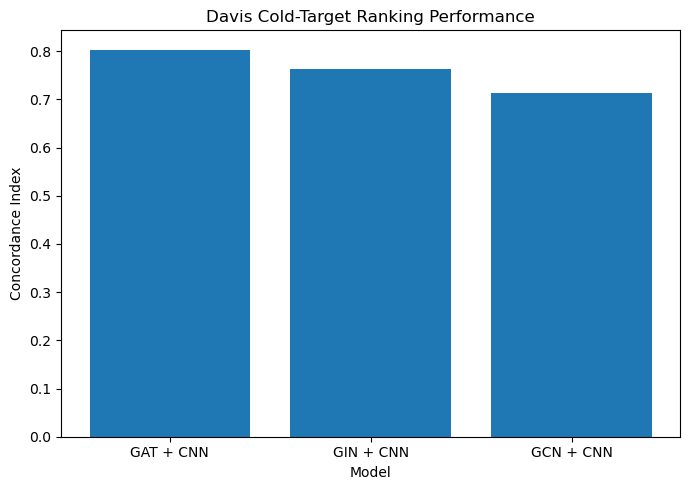

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_cold_target_ci_comparison.png


In [126]:
plt.figure(figsize=(7, 5))

plt.bar(
    cold_target_comparison_df["model"],
    cold_target_comparison_df["concordance_index"],
)

plt.xlabel("Model")
plt.ylabel("Concordance Index")
plt.title("Davis Cold-Target Ranking Performance")
plt.tight_layout()

cold_target_ci_plot_path = (
    PLOTS_DIR
    / "davis_cold_target_ci_comparison.png"
)

plt.savefig(
    cold_target_ci_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(cold_target_ci_plot_path)

# Confirm the outputs

In [127]:
cold_target_comparison_outputs = [
    cold_target_comparison_path,
    cold_target_rmse_plot_path,
    cold_target_ci_plot_path,
]

for output_path in cold_target_comparison_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in cold_target_comparison_outputs
)

print(
    "Cold-target model comparison "
    "completed successfully."
)

davis_cold_target_model_comparison.csv → True
davis_cold_target_rmse_comparison.png → True
davis_cold_target_ci_comparison.png → True
Cold-target model comparison completed successfully.


## Cold-Target Evaluation Complete

GCN + CNN, GAT + CNN and GIN + CNN were trained and tested using unseen protein targets.

The results were saved in one comparison table, and a preliminary cold-target winner was identified.

The next section will compare the random, cold-drug and cold-target results together.

# Final Davis Comparison

This section combines the results from:

- random splitting;
- cold-drug splitting;
- cold-target splitting.

The comparison shows how each model performs under normal evaluation and when predicting unseen drugs or unseen protein targets.

# Load the three comparison tables

In [128]:
random_comparison_df = pd.read_csv(
    METRICS_DIR
    / "davis_random_model_comparison.csv"
)

cold_drug_comparison_df = pd.read_csv(
    METRICS_DIR
    / "davis_cold_drug_model_comparison.csv"
)

cold_target_comparison_df = pd.read_csv(
    METRICS_DIR
    / "davis_cold_target_model_comparison.csv"
)

print("Random comparison:", random_comparison_df.shape)
print("Cold-drug comparison:", cold_drug_comparison_df.shape)
print("Cold-target comparison:", cold_target_comparison_df.shape)

Random comparison: (3, 9)
Cold-drug comparison: (3, 9)
Cold-target comparison: (3, 9)


# Add split names

In [129]:
random_comparison_df["split_type"] = "random"

cold_drug_comparison_df[
    "split_type"
] = "cold_drug"

cold_target_comparison_df[
    "split_type"
] = "cold_target"

# Combine all results

In [130]:
davis_all_splits_df = pd.concat(
    [
        random_comparison_df,
        cold_drug_comparison_df,
        cold_target_comparison_df,
    ],
    ignore_index=True,
)

davis_all_splits_df = davis_all_splits_df[
    [
        "split_type",
        "validation_rank",
        "model",
        "best_validation_mse",
        "test_mse",
        "test_rmse",
        "test_mae",
        "concordance_index",
        "pearson_correlation",
        "trainable_parameters",
    ]
]

display(
    davis_all_splits_df.round(4)
)

,split_type,validation_rank,model,best_validation_mse,test_mse,test_rmse,test_mae,concordance_index,pearson_correlation,trainable_parameters
0,random,1,GAT + CNN,0.4851,0.5100,0.7141,0.4988,0.7963,0.6060,300033
1,random,2,GIN + CNN,0.5568,0.5999,0.7745,0.5101,0.7494,0.4902,348801
2,random,3,GCN + CNN,0.5633,0.6067,0.7789,0.5024,0.7562,0.4829,299265
3,cold_drug,1,GCN + CNN,0.7567,0.8829,0.9397,0.7265,0.7349,0.4536,299265
4,cold_drug,2,GIN + CNN,0.7584,0.8798,0.9380,0.6650,0.7303,0.4327,348801
5,cold_drug,3,GAT + CNN,0.7904,0.9494,0.9744,0.6956,0.6804,0.3496,300033
6,cold_target,1,GAT + CNN,0.5124,0.4059,0.6371,0.3966,0.8031,0.5987,300033
7,cold_target,2,GIN + CNN,0.6342,0.4862,0.6973,0.4272,0.7631,0.5056,348801
8,cold_target,3,GCN + CNN,0.6870,0.5308,0.7286,0.5066,0.7126,0.4040,299265


# Show results in split order

In [131]:
split_order = [
    "random",
    "cold_drug",
    "cold_target",
]

davis_all_splits_df[
    "split_type"
] = pd.Categorical(
    davis_all_splits_df["split_type"],
    categories=split_order,
    ordered=True,
)

davis_all_splits_df = (
    davis_all_splits_df
    .sort_values(
        [
            "split_type",
            "validation_rank",
        ]
    )
    .reset_index(drop=True)
)

display(
    davis_all_splits_df.round(4)
)

,split_type,validation_rank,model,best_validation_mse,test_mse,test_rmse,test_mae,concordance_index,pearson_correlation,trainable_parameters
0,random,1,GAT + CNN,0.4851,0.5100,0.7141,0.4988,0.7963,0.6060,300033
1,random,2,GIN + CNN,0.5568,0.5999,0.7745,0.5101,0.7494,0.4902,348801
2,random,3,GCN + CNN,0.5633,0.6067,0.7789,0.5024,0.7562,0.4829,299265
3,cold_drug,1,GCN + CNN,0.7567,0.8829,0.9397,0.7265,0.7349,0.4536,299265
4,cold_drug,2,GIN + CNN,0.7584,0.8798,0.9380,0.6650,0.7303,0.4327,348801
5,cold_drug,3,GAT + CNN,0.7904,0.9494,0.9744,0.6956,0.6804,0.3496,300033
6,cold_target,1,GAT + CNN,0.5124,0.4059,0.6371,0.3966,0.8031,0.5987,300033
7,cold_target,2,GIN + CNN,0.6342,0.4862,0.6973,0.4272,0.7631,0.5056,348801
8,cold_target,3,GCN + CNN,0.6870,0.5308,0.7286,0.5066,0.7126,0.4040,299265


# Compare RMSE across splits

# Create the RMSE table

In [132]:
rmse_comparison_table = (
    davis_all_splits_df
    .pivot(
        index="model",
        columns="split_type",
        values="test_rmse",
    )
)

rmse_comparison_table = rmse_comparison_table[
    [
        "random",
        "cold_drug",
        "cold_target",
    ]
]

display(
    rmse_comparison_table.round(4)
)

split_type,random,cold_drug,cold_target
model,,,
GAT + CNN,0.7141,0.9744,0.6371
GCN + CNN,0.7789,0.9397,0.7286
GIN + CNN,0.7745,0.9380,0.6973


# Calculate the generalisation gap

In [133]:
generalisation_gap_df = (
    rmse_comparison_table
    .reset_index()
)

generalisation_gap_df[
    "cold_drug_rmse_increase"
] = (
    generalisation_gap_df["cold_drug"]
    - generalisation_gap_df["random"]
)

generalisation_gap_df[
    "cold_target_rmse_increase"
] = (
    generalisation_gap_df["cold_target"]
    - generalisation_gap_df["random"]
)

display(
    generalisation_gap_df.round(4)
)

split_type,model,random,cold_drug,cold_target,cold_drug_rmse_increase,cold_target_rmse_increase
0,GAT + CNN,0.7141,0.9744,0.6371,0.2603,-0.0771
1,GCN + CNN,0.7789,0.9397,0.7286,0.1607,-0.0503
2,GIN + CNN,0.7745,0.9380,0.6973,0.1635,-0.0772


# Create an overall Davis summary

# Calculate average validation rank

In [134]:
davis_robustness_summary = (
    davis_all_splits_df
    .groupby(
        "model",
        observed=True,
    )
    .agg(
        average_validation_rank=(
            "validation_rank",
            "mean",
        ),
        average_test_rmse=(
            "test_rmse",
            "mean",
        ),
        average_test_mae=(
            "test_mae",
            "mean",
        ),
        average_concordance_index=(
            "concordance_index",
            "mean",
        ),
        average_pearson_correlation=(
            "pearson_correlation",
            "mean",
        ),
    )
    .reset_index()
)

davis_robustness_summary = (
    davis_robustness_summary
    .sort_values(
        [
            "average_validation_rank",
            "average_test_rmse",
        ]
    )
    .reset_index(drop=True)
)

davis_robustness_summary.insert(
    0,
    "davis_robustness_rank",
    range(
        1,
        len(davis_robustness_summary) + 1,
    ),
)

display(
    davis_robustness_summary.round(4)
)

,davis_robustness_rank,model,average_validation_rank,average_test_rmse,average_test_mae,average_concordance_index,average_pearson_correlation
0,1,GAT + CNN,1.6667,0.7752,0.5303,0.7599,0.5181
1,2,GIN + CNN,2.0000,0.8033,0.5341,0.7476,0.4762
2,3,GCN + CNN,2.3333,0.8157,0.5785,0.7346,0.4468


# Show the Davis robustness leader

In [135]:
davis_robustness_leader = (
    davis_robustness_summary.iloc[0]
)

print("Davis robustness leader")
print("-----------------------")

print(
    "Model:",
    davis_robustness_leader["model"],
)

print(
    "Average validation rank:",
    round(
        davis_robustness_leader[
            "average_validation_rank"
        ],
        4,
    ),
)

print(
    "Average test RMSE:",
    round(
        davis_robustness_leader[
            "average_test_rmse"
        ],
        4,
    ),
)

print(
    "Average concordance index:",
    round(
        davis_robustness_leader[
            "average_concordance_index"
        ],
        4,
    ),
)

Davis robustness leader
-----------------------
Model: GAT + CNN
Average validation rank: 1.6667
Average test RMSE: 0.7752
Average concordance index: 0.7599


# Save the complete comparison

In [136]:
davis_all_splits_path = (
    METRICS_DIR
    / "davis_all_splits_model_comparison.csv"
)

davis_all_splits_df.to_csv(
    davis_all_splits_path,
    index=False,
)

print("Saved to:")
print(davis_all_splits_path)

Saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_all_splits_model_comparison.csv


# Save the robustness summary

In [137]:
davis_robustness_summary_path = (
    METRICS_DIR
    / "davis_model_robustness_summary.csv"
)

davis_robustness_summary.to_csv(
    davis_robustness_summary_path,
    index=False,
)

print("Saved to:")
print(davis_robustness_summary_path)

Saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_model_robustness_summary.csv


# Save the generalisation-gap table

In [138]:
generalisation_gap_path = (
    METRICS_DIR
    / "davis_generalisation_gap.csv"
)

generalisation_gap_df.to_csv(
    generalisation_gap_path,
    index=False,
)

print("Saved to:")
print(generalisation_gap_path)

Saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/metrics/davis_generalisation_gap.csv


# Create final Davis plots

# Plot RMSE across all splits

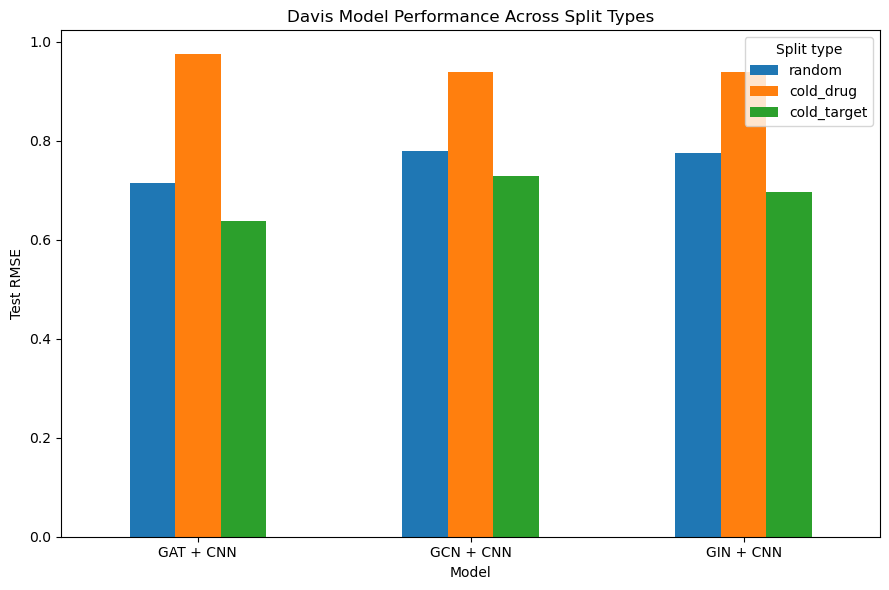

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_all_splits_rmse_comparison.png


In [139]:
rmse_plot_data = (
    davis_all_splits_df
    .pivot(
        index="model",
        columns="split_type",
        values="test_rmse",
    )
)

rmse_plot_data = rmse_plot_data[
    [
        "random",
        "cold_drug",
        "cold_target",
    ]
]

rmse_plot_data.plot(
    kind="bar",
    figsize=(9, 6),
)

plt.xlabel("Model")
plt.ylabel("Test RMSE")
plt.title("Davis Model Performance Across Split Types")
plt.xticks(rotation=0)
plt.legend(title="Split type")
plt.tight_layout()

davis_all_splits_rmse_plot = (
    PLOTS_DIR
    / "davis_all_splits_rmse_comparison.png"
)

plt.savefig(
    davis_all_splits_rmse_plot,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(davis_all_splits_rmse_plot)

# Plot concordance index across all splits

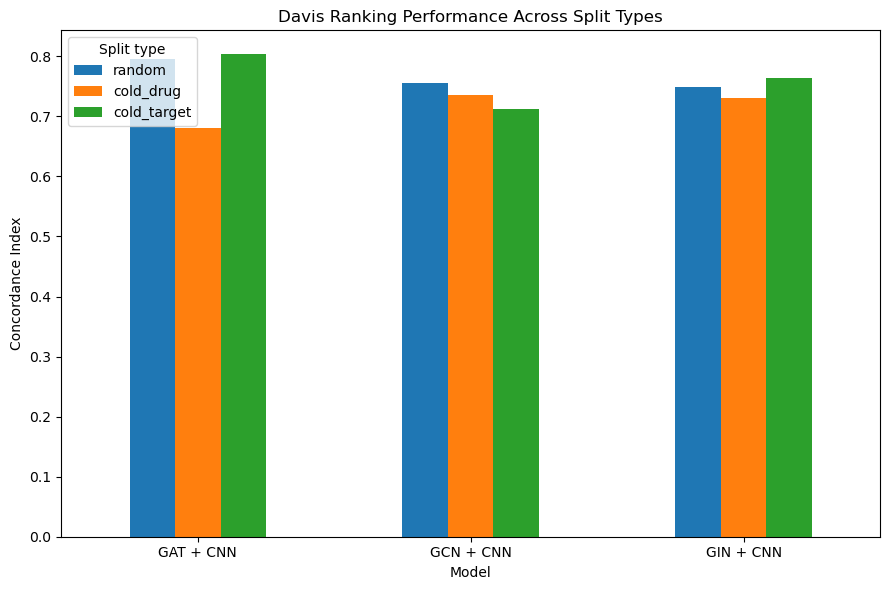

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_all_splits_ci_comparison.png


In [140]:
ci_plot_data = (
    davis_all_splits_df
    .pivot(
        index="model",
        columns="split_type",
        values="concordance_index",
    )
)

ci_plot_data = ci_plot_data[
    [
        "random",
        "cold_drug",
        "cold_target",
    ]
]

ci_plot_data.plot(
    kind="bar",
    figsize=(9, 6),
)

plt.xlabel("Model")
plt.ylabel("Concordance Index")
plt.title("Davis Ranking Performance Across Split Types")
plt.xticks(rotation=0)
plt.legend(title="Split type")
plt.tight_layout()

davis_all_splits_ci_plot = (
    PLOTS_DIR
    / "davis_all_splits_ci_comparison.png"
)

plt.savefig(
    davis_all_splits_ci_plot,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(davis_all_splits_ci_plot)

# Plot the RMSE generalisation gap

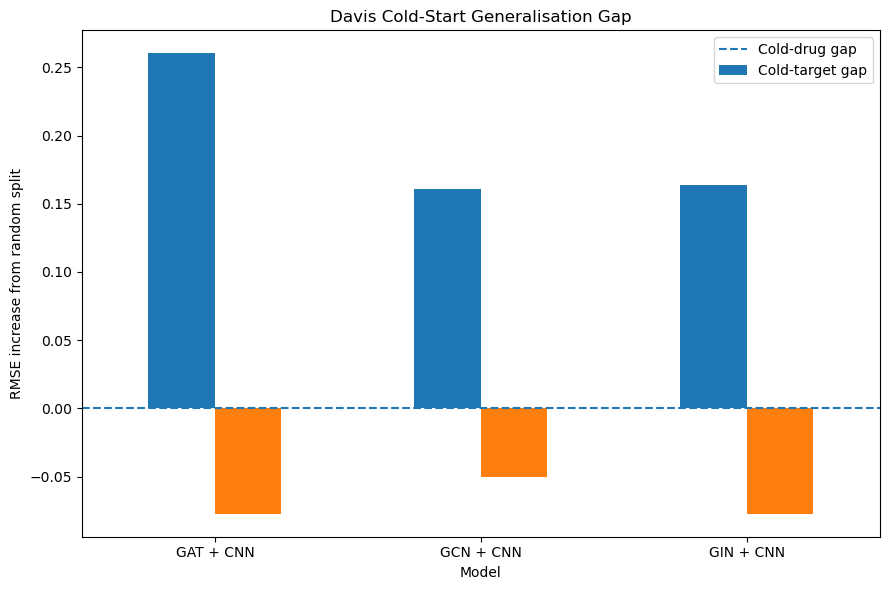

Plot saved to:
/Users/bikashlimbu/Library/CloudStorage/OneDrive2-BuckinghamshireNewUniversity/Dissertation/model/aml_gnn_dti_repurposing/results/plots/davis_rmse_generalisation_gap.png


In [141]:
gap_plot_data = (
    generalisation_gap_df
    .set_index("model")
    [
        [
            "cold_drug_rmse_increase",
            "cold_target_rmse_increase",
        ]
    ]
)

gap_plot_data.plot(
    kind="bar",
    figsize=(9, 6),
)

plt.axhline(
    y=0,
    linestyle="--",
)

plt.xlabel("Model")
plt.ylabel("RMSE increase from random split")
plt.title("Davis Cold-Start Generalisation Gap")
plt.xticks(rotation=0)
plt.legend(
    [
        "Cold-drug gap",
        "Cold-target gap",
    ]
)
plt.tight_layout()

generalisation_gap_plot = (
    PLOTS_DIR
    / "davis_rmse_generalisation_gap.png"
)

plt.savefig(
    generalisation_gap_plot,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Plot saved to:")
print(generalisation_gap_plot)

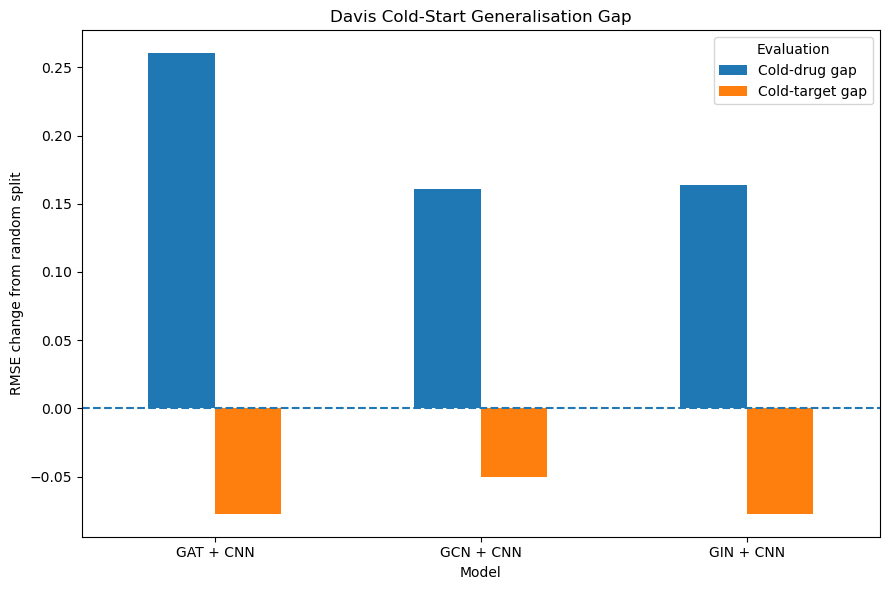

In [143]:
gap_plot_data = (
    generalisation_gap_df
    .set_index("model")
    [
        [
            "cold_drug_rmse_increase",
            "cold_target_rmse_increase",
        ]
    ]
    .rename(
        columns={
            "cold_drug_rmse_increase": "Cold-drug gap",
            "cold_target_rmse_increase": "Cold-target gap",
        }
    )
)

ax = gap_plot_data.plot(
    kind="bar",
    figsize=(9, 6),
)

ax.axhline(
    y=0,
    linestyle="--",
    label="_nolegend_",
)

ax.set_xlabel("Model")
ax.set_ylabel("RMSE change from random split")
ax.set_title("Davis Cold-Start Generalisation Gap")

plt.xticks(rotation=0)
plt.legend(title="Evaluation")
plt.tight_layout()

generalisation_gap_plot = (
    PLOTS_DIR
    / "davis_rmse_generalisation_gap.png"
)

plt.savefig(
    generalisation_gap_plot,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Confirm all outputs

In [142]:
final_davis_outputs = [
    davis_all_splits_path,
    davis_robustness_summary_path,
    generalisation_gap_path,
    davis_all_splits_rmse_plot,
    davis_all_splits_ci_plot,
    generalisation_gap_plot,
]

for output_path in final_davis_outputs:
    print(
        output_path.name,
        "→",
        output_path.exists(),
    )

assert all(
    output_path.exists()
    for output_path in final_davis_outputs
)

print(
    "Final Davis comparison completed successfully."
)

davis_all_splits_model_comparison.csv → True
davis_model_robustness_summary.csv → True
davis_generalisation_gap.csv → True
davis_all_splits_rmse_comparison.png → True
davis_all_splits_ci_comparison.png → True
davis_rmse_generalisation_gap.png → True
Final Davis comparison completed successfully.


# Davis Cold-Start Evaluation Complete

The three models were compared using:

- random splitting;
- cold-drug splitting;
- cold-target splitting.

The final Davis analysis includes:

- prediction-error comparisons;
- ranking-performance comparisons;
- cold-start generalisation gaps;
- an overall Davis robustness ranking.

The Davis robustness leader is not yet the final dissertation model. The next stage will repeat the experiments using the KIBA dataset.